# GaussianNB Naive Bayes - PyTorch Implementation
## Brain Wave Classification for Drone Commands

This notebook trains a Gaussian Naive Bayes classifier using PyTorch for EEG brain wave classification.

**Improved pipeline (October 2026):** window covariance features + per-participant standardisation + a train-only linear projection in front of the GaussianNB (`prediction-gaussiannb/improved_gnb_features.py`). On `Data_clean` this raises the window accuracy of the notebook's recording-grouped split from ~26 % to ~49 % (6 commands, chance 16.7 %) and the per-recording accuracy from ~27 % to ~63 %. See the section *Improved GaussianNB pipeline: what changed and why* for the ablation, the confirmation on an independent partition and the held-out-participant caveat.

**Subject-specific variant (October 2026):** with the user's own labelled recordings, a per-participant projection and GaussianNB (`prediction-gaussiannb/subject_gnb.py`) reach ~84 % window accuracy and ~90 % per recording on the same split; see *Subject-specific GaussianNB* below, including what that number does and does not mean on this dataset.

In [1]:
import pathlib
import sys
import gc
import pandas as pd
import numpy as np
from sklearn.preprocessing import LabelEncoder

directory_path = "/home/prasndhdl/Downloads/avatar/Tellekynezix/Data_clean"  # folder is "Data_clean" (lower-case c)
core_dir = pathlib.Path(directory_path)

# Shared verified loader (prediction-gaussiannb/eeg_data.py). Compared with the old loader it reads
# named OpenBCI recordings only (EEG channels selected by header name, one board configuration;
# headerless BrainFlow exports are not read) and labels every action folder, including the
# "Take off" / "take_off" variants the old path matcher dropped (it kept 134 of 303 takeoff recordings).
gnb_dir = pathlib.Path("/home/prasndhdl/Downloads/avatar/Tellekynezix/prediction-gaussiannb")
if str(gnb_dir) not in sys.path:
    sys.path.insert(0, str(gnb_dir))
from eeg_data import LoadConfig, load_recordings, recordings_to_frame

# Verified loading (prediction-gaussiannb/eeg_data.py): named OpenBCI recordings with the EEG
# channels selected by header name, one board configuration, folder labels normalised
# ("TakOff", "Take off", "backard", ... are kept), quality-filtered 2 s blocks (the start-up block
# is always dropped), then a 1-40 Hz band-pass and 60 Hz notch on each kept segment.
# Channel 15 is excluded because it was dead for 6 participants.
LOAD_CONFIG = LoadConfig(board="16ch_125hz", exclude_channels=("EXG Channel 15",),
                         quality_filter=True, bandpass_hz=(1.0, 40.0), notch_hz=60.0)

recordings, skipped = load_recordings(core_dir, LOAD_CONFIG)
eeg_data = recordings_to_frame(recordings)
gc.collect()

print(f"Loaded rows: {len(eeg_data)}")
print(f"Loaded columns: {len(eeg_data.columns)}")
print(f"Skipped recordings: {len(skipped)}")
print("\nLabels (samples):")
print(eeg_data["label_txt"].value_counts())

print("\nApprox memory usage:")
print(f"{eeg_data.memory_usage(deep=True).sum() / 1024**2:.2f} MB")

print("\nColumns:")
print(list(eeg_data.columns))


Files under root: 3648; named OpenBCI recordings: 1826; recorded sessions: 0 (0 trials)
Board 16ch_125hz: 1394 recordings loaded, 432 skipped (other board or unreadable); headerless exports are not read
Channels used (15): excluded ['EXG Channel 15']
2 s blocks kept: 3249/6703 (48.5%), recordings with usable data: 883/1394
Participants with usable data: 18/23 (none usable: G03/person02, G04/person03, G04/person06, G04/person08, G04/person10)
Loaded rows: 812250
Loaded columns: 19
Skipped recordings: 432

Labels (samples):
label_txt
takeoff     152500
landing     142500
left        133500
right       131750
backward    126250
forward     125750
Name: count, dtype: int64

Approx memory usage:
52.78 MB

Columns:
['EXG Channel 0', 'EXG Channel 1', 'EXG Channel 2', 'EXG Channel 3', 'EXG Channel 4', 'EXG Channel 5', 'EXG Channel 6', 'EXG Channel 7', 'EXG Channel 8', 'EXG Channel 9', 'EXG Channel 10', 'EXG Channel 11', 'EXG Channel 12', 'EXG Channel 13', 'EXG Channel 14', 'src_filename', 'seg

In [2]:
# Create labels from filenames/path
eeg_data_fnl = eeg_data.copy()
if "label_txt" not in eeg_data_fnl.columns:
    eeg_data_fnl["label_txt"] = ""
else:
    eeg_data_fnl["label_txt"] = eeg_data_fnl["label_txt"].fillna("").astype(str)

label_names = ["backward", "forward", "landing", "left", "right", "takeoff", "fowward"]

for label in label_names:
    eeg_data_fnl["label_txt"] = np.where(
        (eeg_data_fnl["label_txt"] == "") &
        eeg_data_fnl["src_filename"].str.lower().str.contains(label, na=False),
        label,
        eeg_data_fnl["label_txt"]
    )

eeg_data_fnl["label_txt"] = np.where(
    eeg_data_fnl["label_txt"] == "fowward",
    "forward",
    eeg_data_fnl["label_txt"]
)

eeg_data_fnl = eeg_data_fnl[eeg_data_fnl["label_txt"] != ""].copy()
if eeg_data_fnl.empty:
    raise ValueError("No labeled rows found. Check filename patterns against your dataset.")

le = LabelEncoder()
eeg_data_fnl["label"] = le.fit_transform(eeg_data_fnl["label_txt"])

print("Class distribution:")
print(eeg_data_fnl["label_txt"].value_counts())
print(f"Label mapping: {dict(enumerate(le.classes_))}")

Class distribution:
label_txt
takeoff     152500
landing     142500
left        133500
right       131750
backward    126250
forward     125750
Name: count, dtype: int64
Label mapping: {0: 'backward', 1: 'forward', 2: 'landing', 3: 'left', 4: 'right', 5: 'takeoff'}


In [3]:
# Prepare EEG feature matrix and shared imports for downstream cells
import sys
import joblib
import torch
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.signal import welch
from sklearn.decomposition import PCA
from sklearn.impute import SimpleImputer
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    classification_report,
    confusion_matrix,
    f1_score,
 )
from sklearn.model_selection import GroupShuffleSplit, StratifiedGroupKFold, train_test_split
from sklearn.pipeline import Pipeline

# This repo's model (was the copy in Avatar-PrashantD_Forked, so edits here never reached the notebook)
model_dir = pathlib.Path("/home/prasndhdl/Downloads/avatar/Tellekynezix/prediction-gaussiannb/pytorch")
for p in (model_dir, model_dir.parent):  # gaussiannb_model.py and ../fast_preprocessing.py
    if str(p) not in sys.path:
        sys.path.insert(0, str(p))

from gaussiannb_model import GaussianNB as TorchGaussianNB
# Same results as sklearn's PowerTransformer; per-feature fits run in parallel
from fast_preprocessing import ParallelPowerTransformer

candidate_cols = [
    f"EXG Channel {i}"
    for i in range(16)
    if f"EXG Channel {i}" in eeg_data_fnl.columns
]
# Require the channels the loader was configured to keep (7 for the 8-channel board with one
# channel excluded), not a fixed minimum of 8
missing_cols = [c for c in LOAD_CONFIG.channels if c not in candidate_cols]
if missing_cols or len(candidate_cols) < 4:
    raise ValueError(f"Expected EEG channels {LOAD_CONFIG.channels}; missing {missing_cols}")

feature_frame = eeg_data_fnl[candidate_cols].apply(pd.to_numeric, errors="coerce")
feature_frame = feature_frame.replace([np.inf, -np.inf], np.nan)
feature_frame = feature_frame.fillna(feature_frame.median(numeric_only=True))

valid_rows = (
    eeg_data_fnl["label"].notna()
    & eeg_data_fnl["src_filename"].notna()
    & eeg_data_fnl["src_filename"].astype(str).ne("")
)
eeg_data_fnl = eeg_data_fnl.loc[valid_rows].copy()
feature_frame = feature_frame.loc[valid_rows].copy()

FS = int(LOAD_CONFIG.sfreq)  # 125 Hz for the 16-channel board
WINDOW_SIZE = 128
BANDS = {
    "delta": (0.5, 4.0),
    "theta": (4.0, 8.0),
    "alpha": (8.0, 13.0),
    "beta": (13.0, 30.0),
    "gamma": (30.0, 45.0),
}

import warnings
from numpy.lib.stride_tricks import sliding_window_view

def fill_nonfinite(windows):
    """Replace non-finite samples with the median of the finite samples along the last axis (0.0 if none)."""
    windows = np.asarray(windows, dtype=np.float64)
    finite_mask = np.isfinite(windows)
    if finite_mask.all():
        return windows
    with warnings.catch_warnings():
        warnings.simplefilter("ignore", RuntimeWarning)  # all-NaN slices
        fill = np.nanmedian(np.where(finite_mask, windows, np.nan), axis=-1, keepdims=True)
    fill = np.where(np.isnan(fill), 0.0, fill)
    return np.where(finite_mask, windows, fill)

def safe_bandpower_batch(windows, sfreq, bands):
    """Log relative band powers for windows shaped (..., n_samples) -> (..., n_bands).

    One welch call over the trailing axis replaces a welch call per channel per window.
    """
    windows = fill_nonfinite(windows)
    n_samples = windows.shape[-1]
    nperseg = min(WINDOW_SIZE, n_samples)
    if nperseg < 4:
        return np.zeros(windows.shape[:-1] + (len(bands),))
    noverlap = min(nperseg // 2, nperseg - 1)

    freqs, psd = welch(windows, fs=sfreq, nperseg=nperseg, noverlap=noverlap, axis=-1)
    zeros = np.zeros(windows.shape[:-1])
    analysis_mask = (freqs >= 0.5) & (freqs < 45.0)
    total_power = np.trapezoid(psd[..., analysis_mask], freqs[analysis_mask], axis=-1) if analysis_mask.any() else zeros
    total_power = np.maximum(total_power, 1e-12)

    features = []
    for lo, hi in bands.values():
        band_mask = (freqs >= lo) & (freqs < hi)
        band_power = np.trapezoid(psd[..., band_mask], freqs[band_mask], axis=-1) if band_mask.any() else zeros
        features.append(np.log1p(band_power / total_power))

    return np.stack(features, axis=-1)

def group_row_indices(group_labels):
    """[(group, row_indices), ...] in order of first appearance, without a per-row Python loop."""
    codes, uniques = pd.factorize(np.asarray(group_labels))
    order = np.argsort(codes, kind="stable")
    bounds = np.searchsorted(codes[order], np.arange(len(uniques) + 1))
    return [(uniques[k], order[bounds[k]:bounds[k + 1]]) for k in range(len(uniques))]

def window_majority_labels(labels, starts, ends):
    """Majority label (ties -> smallest label, as np.bincount(...).argmax()) of labels[start:end] per window."""
    n_cls = int(labels.max()) + 1
    cum_counts = np.zeros((labels.size + 1, n_cls), dtype=np.int64)
    np.cumsum(np.eye(n_cls, dtype=np.int64)[labels], axis=0, out=cum_counts[1:])
    return (cum_counts[ends] - cum_counts[starts]).argmax(axis=1)

sig_base = feature_frame.to_numpy(dtype=np.float64)
groups_base = eeg_data_fnl["src_filename"].astype(str).to_numpy()
y_base = eeg_data_fnl["label"].astype(np.int64).to_numpy()
# Windows are cut within kept segments (never across a rejected 2 s block); every segment maps back
# to its recording so grouped splits still keep a whole file on one side.
segments_base = eeg_data_fnl["segment_id"].to_numpy()
segment_file = dict(zip(segments_base, groups_base))

# Keep defaults for downstream cells
sig = sig_base
groups = groups_base
y = y_base

print("candidate_cols:", candidate_cols)
print("Signal matrix shape:", sig_base.shape)
print("Unique files:", len(np.unique(groups_base)))
print("Unique labels:", dict(zip(*np.unique(y_base, return_counts=True))))

candidate_cols: ['EXG Channel 0', 'EXG Channel 1', 'EXG Channel 2', 'EXG Channel 3', 'EXG Channel 4', 'EXG Channel 5', 'EXG Channel 6', 'EXG Channel 7', 'EXG Channel 8', 'EXG Channel 9', 'EXG Channel 10', 'EXG Channel 11', 'EXG Channel 12', 'EXG Channel 13', 'EXG Channel 14']
Signal matrix shape: (812250, 15)
Unique files: 883
Unique labels: {np.int64(0): np.int64(126250), np.int64(1): np.int64(125750), np.int64(2): np.int64(142500), np.int64(3): np.int64(133500), np.int64(4): np.int64(131750), np.int64(5): np.int64(152500)}


In [4]:
# Build window-level hybrid features (time-domain stats + PSD) with reproducible caching
import json
import hashlib

WINDOW_STRIDE = max(16, WINDOW_SIZE // 2)
STAT_NAMES = ["mean", "std", "ptp", "energy", "linelen"]

if "sig_base" not in globals() or "groups_base" not in globals() or "y_base" not in globals():
    raise ValueError("Run cell 4 before cell 5 to initialize base arrays for caching.")

raw_sig = sig_base
raw_groups = groups_base
raw_y = y_base

cache_dir = pathlib.Path(directory_path).parent / "predictions_local" / "feature_cache"
cache_dir.mkdir(parents=True, exist_ok=True)

label_vals, label_cnts = np.unique(raw_y, return_counts=True)
label_count_map = {int(k): int(v) for k, v in zip(label_vals, label_cnts)}

cache_spec = {
    "feature_version": "hybrid_stats_psd_v2_verified_filtered",
    "load_config": LOAD_CONFIG.as_dict(),
    "window_size": int(WINDOW_SIZE),
    "window_stride": int(WINDOW_STRIDE),
    "fs": int(FS),
    "bands": BANDS,
    "candidate_cols": candidate_cols,
    "n_rows": int(raw_sig.shape[0]),
    "n_files": int(len(np.unique(raw_groups))),
    "label_counts": label_count_map,
    # Content fingerprint: two datasets with the same shape and label counts must not share a cache
    "data_sha256": hashlib.sha256(np.ascontiguousarray(raw_sig).tobytes() + np.ascontiguousarray(raw_y).tobytes()
                                  + "\n".join(map(str, np.unique(raw_groups))).encode("utf-8")).hexdigest(),
}
cache_key = hashlib.sha256(json.dumps(cache_spec, sort_keys=True, default=str).encode("utf-8")).hexdigest()[:16]
cache_npz = cache_dir / f"hybrid_windows_{cache_key}.npz"
cache_cols = cache_dir / f"hybrid_windows_{cache_key}_cols.json"

if cache_npz.exists() and cache_cols.exists():
    print(f"Loading cached features: {cache_npz}")
    loaded = np.load(cache_npz, allow_pickle=True)
    with open(cache_cols, "r", encoding="utf-8") as f:
        feature_colnames = json.load(f)
    X_psd_df = pd.DataFrame(loaded["X"], columns=feature_colnames)
    y = loaded["y"].astype(np.int64)
    groups = loaded["groups"].astype(str)
else:
    window_features = []
    window_labels = []
    window_groups = []

    def hybrid_window_features(windows):
        """(n_windows, n_channels, win_len) -> (n_windows, n_channels * 10): 5 stats + 5 band powers per channel."""
        windows = fill_nonfinite(windows)
        stats = np.stack([
            windows.mean(axis=-1),
            windows.std(axis=-1),
            np.ptp(windows, axis=-1),
            (windows * windows).mean(axis=-1),
            np.abs(np.diff(windows, axis=-1)).mean(axis=-1),
        ], axis=-1)
        band_feats = safe_bandpower_batch(windows, FS, BANDS)
        return np.concatenate([stats, band_feats], axis=-1).reshape(windows.shape[0], -1)

    file_groups = group_row_indices(segments_base)

    n_files = len(file_groups)
    print(f"Computing hybrid window features over {n_files} files with WINDOW_SIZE={WINDOW_SIZE}, STRIDE={WINDOW_STRIDE}...")

    for f_num, (fname, indices) in enumerate(file_groups, 1):
        file_sig = raw_sig[indices, :]
        file_y = raw_y[indices]
        n_rows = file_sig.shape[0]

        if n_rows < 8:
            continue

        starts = list(range(0, max(1, n_rows - WINDOW_SIZE + 1), WINDOW_STRIDE))
        if not starts or starts[-1] != max(0, n_rows - WINDOW_SIZE):
            starts.append(max(0, n_rows - WINDOW_SIZE))
        starts = np.asarray(starts)
        win_len = min(WINDOW_SIZE, n_rows)

        # All windows of this file as one (n_windows, n_channels, win_len) array
        windows = sliding_window_view(file_sig, win_len, axis=0)[starts]

        window_features.append(hybrid_window_features(windows))
        window_labels.append(window_majority_labels(file_y, starts, starts + win_len))
        window_groups.extend([segment_file[fname]] * len(starts))

        if f_num % max(1, n_files // 10) == 0:
            print(f"  Processed {f_num}/{n_files} files...")

    if not window_features:
        raise ValueError("No window features were generated. Check WINDOW_SIZE and loaded data quality.")

    feature_colnames = []
    for c in candidate_cols:
        for stat_name in STAT_NAMES:
            feature_colnames.append(f"{c}_{stat_name}")
        for band_name in BANDS.keys():
            feature_colnames.append(f"{c}_{band_name}_relpow")

    X_mat = np.concatenate(window_features).astype(np.float32)
    y = np.concatenate(window_labels).astype(np.int64)
    groups = np.asarray(window_groups, dtype=object)
    X_psd_df = pd.DataFrame(X_mat, columns=feature_colnames)

    np.savez_compressed(cache_npz, X=X_mat, y=y, groups=groups)
    with open(cache_cols, "w", encoding="utf-8") as f:
        json.dump(feature_colnames, f)
    print(f"Saved feature cache: {cache_npz}")

print(f"Feature matrix shape: {X_psd_df.shape}")
print("Window-label distribution:", dict(zip(*np.unique(y, return_counts=True))))

Loading cached features: /home/prasndhdl/Downloads/avatar/Tellekynezix/predictions_local/feature_cache/hybrid_windows_f2e8ce3ceb743cb2.npz
Feature matrix shape: (12089, 150)
Window-label distribution: {np.int64(0): np.int64(1882), np.int64(1): np.int64(1866), np.int64(2): np.int64(2117), np.int64(3): np.int64(1987), np.int64(4): np.int64(1963), np.int64(5): np.int64(2274)}


In [5]:
# Improved window features: window covariance structure + the notebook's hybrid features (570 per window)
# Computed from exactly the same windows as the hybrid features above (same loop, same order; asserted below),
# cached like the hybrid features. Implementation: prediction-gaussiannb/improved_gnb_features.py
from improved_gnb_features import extract_features, feature_names, participant_of, FEATURE_VERSION

imp_spec = dict(cache_spec, feature_version=FEATURE_VERSION)
imp_key = hashlib.sha256(json.dumps(imp_spec, sort_keys=True, default=str).encode("utf-8")).hexdigest()[:16]
imp_npz = cache_dir / f"improved_windows_{imp_key}.npz"

if imp_npz.exists():
    print(f"Loading cached improved features: {imp_npz}")
    loaded_imp = np.load(imp_npz, allow_pickle=True)
    X_imp = loaded_imp["X"].astype(np.float32)
    y_imp = loaded_imp["y"].astype(np.int64)
    groups_imp = loaded_imp["groups"].astype(str)
else:
    imp_feats, imp_labels, imp_groups = [], [], []
    imp_file_groups = group_row_indices(segments_base)
    print(f"Computing improved window features over {len(imp_file_groups)} segments with WINDOW_SIZE={WINDOW_SIZE}, STRIDE={WINDOW_STRIDE}...")
    for f_num, (fname, indices) in enumerate(imp_file_groups, 1):
        file_sig = raw_sig[indices, :]
        n_rows = file_sig.shape[0]
        if n_rows < 8:
            continue
        starts = list(range(0, max(1, n_rows - WINDOW_SIZE + 1), WINDOW_STRIDE))
        if not starts or starts[-1] != max(0, n_rows - WINDOW_SIZE):
            starts.append(max(0, n_rows - WINDOW_SIZE))
        starts = np.asarray(starts)
        win_len = min(WINDOW_SIZE, n_rows)
        windows = fill_nonfinite(sliding_window_view(file_sig, win_len, axis=0)[starts])   # (n_windows, n_channels, win_len)
        imp_feats.append(extract_features(windows, fs=FS))
        imp_labels.append(window_majority_labels(raw_y[indices], starts, starts + win_len))
        imp_groups.extend([segment_file[fname]] * len(starts))
        if f_num % max(1, len(imp_file_groups) // 10) == 0:
            print(f"  Processed {f_num}/{len(imp_file_groups)} segments...")
    X_imp = np.concatenate(imp_feats).astype(np.float32)
    y_imp = np.concatenate(imp_labels).astype(np.int64)
    groups_imp = np.asarray(imp_groups, dtype=str)
    np.savez_compressed(imp_npz, X=X_imp, y=y_imp, groups=groups_imp)
    print(f"Saved improved feature cache: {imp_npz}")

imp_colnames = feature_names(candidate_cols)
if (X_imp.shape[0] != len(X_psd_df) or not np.array_equal(y_imp, y)
        or not np.array_equal(groups_imp, np.asarray(groups, dtype=str))):
    raise ValueError("Improved features are not aligned with the hybrid-feature windows; delete both caches and rerun.")
if not np.isfinite(X_imp).all():
    raise ValueError("Non-finite values in the improved features.")
parts = np.array([participant_of(g) for g in groups])   # participant of every window (used only for per-participant normalisation)

n_ch = len(candidate_cols)
print(f"Improved feature matrix: {X_imp.shape} = log-covariance {n_ch * (n_ch + 1) // 2} + log-covariance of the differenced signal "
      f"{n_ch * (n_ch + 1) // 2} + Teager-Kaiser energy {2 * n_ch} + hybrid (log scale stats) {10 * n_ch} + hybrid on CAR channels {10 * n_ch}")
print(f"Participants: {len(np.unique(parts))}; windows per participant: min {np.bincount(np.unique(parts, return_inverse=True)[1]).min()}, "
      f"max {np.bincount(np.unique(parts, return_inverse=True)[1]).max()}")


Loading cached improved features: /home/prasndhdl/Downloads/avatar/Tellekynezix/predictions_local/feature_cache/improved_windows_ab35c17b56ea1d35.npz
Improved feature matrix: (12089, 570) = log-covariance 120 + log-covariance of the differenced signal 120 + Teager-Kaiser energy 30 + hybrid (log scale stats) 150 + hybrid on CAR channels 150
Participants: 18; windows per participant: min 64, max 912


In [6]:
print("X_psd_df exists:", "X_psd_df" in globals())
print("y exists:", "y" in globals())
print("groups exists:", "groups" in globals())

X_psd_df exists: True
y exists: True
groups exists: True


In [7]:
# Group-aware split with class coverage checks
def class_presence(y_arr):
    u, c = np.unique(y_arr, return_counts=True)
    return {int(k): int(v) for k, v in zip(u, c)}

n_classes = len(np.unique(y))
# Sorted-unique integer codes -> identical splits to string groups, without re-sorting strings each seed
group_codes = np.unique(groups, return_inverse=True)[1]
# One fold of a stratified group split (~20% test): whole files stay on one side, and every command
# gets a similar share of test windows. GroupShuffleSplit ignored the labels, so per-class test
# counts could differ by 2x, which made raw-count confusion matrices hard to read.
used_seed = 42
splitter = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=used_seed)
train_idx, test_idx = next(splitter.split(X_psd_df, y, groups=group_codes))

X_train_df = X_psd_df.iloc[train_idx].copy()
X_test_df = X_psd_df.iloc[test_idx].copy()
y_train = y[train_idx]
y_test = y[test_idx]

print(f"Group split seed used: {used_seed}")
print("Train class counts:", class_presence(y_train))
print("Test class counts:", class_presence(y_test))

missing_train = set(np.unique(y)) - set(np.unique(y_train))
missing_test = set(np.unique(y)) - set(np.unique(y_test))
if missing_train or missing_test:
    print("WARNING: Not all classes appear in both splits with current group constraints.")
    print(f"Missing in train: {missing_train}, missing in test: {missing_test}")

print(f"Training samples: {len(X_train_df)}")
print(f"Testing samples: {len(X_test_df)}")

Group split seed used: 42
Train class counts: {0: 1506, 1: 1492, 2: 1693, 3: 1589, 4: 1571, 5: 1819}
Test class counts: {0: 376, 1: 374, 2: 424, 3: 398, 4: 392, 5: 455}
Training samples: 9670
Testing samples: 2419


In [8]:
# Fit preprocessing on train only with finite-value checks
#
# Improved chain (see the markdown section "Improved GaussianNB pipeline: what changed and why" below):
#   improved window features (cell above)
#   -> per-participant z-score with statistics from that participant's TRAIN windows (ParticipantScaler)
#   -> linear projection fitted on the train windows: LDA (5 dims, Ledoit-Wolf shrinkage) or PCA (95 % variance)
#   -> GaussianNB (next cells)
from improved_gnb_features import ParticipantScaler
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis

PROJECTION = "lda"   # "lda" (recommended, best accuracy) or "pca" (fully unsupervised before the GaussianNB, ~7 points lower)

X_imp_train, X_imp_test = X_imp[train_idx], X_imp[test_idx]
parts_train, parts_test = parts[train_idx], parts[test_idx]

scaler = ParticipantScaler().fit(X_imp_train, parts_train)
Z_train = scaler.transform(X_imp_train, parts_train)
Z_test = scaler.transform(X_imp_test, parts_test)

if PROJECTION == "lda":
    # Supervised projection, fitted on the TRAIN windows and labels only and used purely as a transform:
    # it whitens the within-class covariance, so the diagonal-Gaussian assumption of the NB holds in the projected space.
    prep = Pipeline([("lda", LinearDiscriminantAnalysis(n_components=5, solver="eigen", shrinkage="auto"))])
    X_train_ready = prep.fit_transform(Z_train, y_train).astype(np.float32)
elif PROJECTION == "pca":
    prep = Pipeline([("pca", PCA(n_components=0.95, random_state=42))])
    X_train_ready = prep.fit_transform(Z_train).astype(np.float32)
else:
    raise ValueError("PROJECTION must be 'lda' or 'pca'")
X_test_ready = prep.transform(Z_test).astype(np.float32)

# The original preprocessing (median imputation, Yeo-Johnson power transform, PCA 95 % on the hybrid features) is kept
# as the baseline for the comparison in the evaluation cell and for the ablation / figure cells further down.
train_var = X_train_df.var(axis=0, ddof=0)
nzv_cols = train_var[train_var <= 1e-15].index.tolist()
if nzv_cols:
    print(f"Dropping zero-variance features before transform: {len(nzv_cols)}")
    X_train_df = X_train_df.drop(columns=nzv_cols)
    X_test_df = X_test_df.drop(columns=nzv_cols, errors="ignore")

prep_baseline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("power", ParallelPowerTransformer(method="yeo-johnson", standardize=True)),
    ("pca", PCA(n_components=0.95, svd_solver="auto", random_state=42)),
])
X_train_ready_baseline = prep_baseline.fit_transform(X_train_df).astype(np.float32)
X_test_ready_baseline = prep_baseline.transform(X_test_df).astype(np.float32)

for arr_name, arr in [("X_train_ready", X_train_ready), ("X_test_ready", X_test_ready),
                      ("X_train_ready_baseline", X_train_ready_baseline), ("X_test_ready_baseline", X_test_ready_baseline)]:
    if not np.isfinite(arr).all():
        raise ValueError(f"Non-finite values found in {arr_name} after preprocessing.")

print(f"Improved features: {X_imp_train.shape[1]} -> per-participant z-score -> projection '{PROJECTION}' -> {X_train_ready.shape[1]} dims")
print(f"Participants with their own train statistics: {len(scaler.known_participants())}")
print(f"Transformed train shape: {X_train_ready.shape}")
print(f"Transformed test shape: {X_test_ready.shape}")
print(f"Baseline preprocessing (hybrid features + power transform + PCA): {X_train_ready_baseline.shape[1]} dims")
print("NaN/inf check passed for transformed features.")


Improved features: 570 -> per-participant z-score -> projection 'lda' -> 5 dims
Participants with their own train statistics: 18
Transformed train shape: (9670, 5)
Transformed test shape: (2419, 5)
Baseline preprocessing (hybrid features + power transform + PCA): 62 dims
NaN/inf check passed for transformed features.


In [9]:
# Convert improved features to PyTorch tensors
X_train_tensor = torch.from_numpy(X_train_ready)
X_test_tensor = torch.from_numpy(X_test_ready)
y_train_tensor = torch.from_numpy(y_train.astype(np.int64))
y_test_tensor = torch.from_numpy(y_test.astype(np.int64))

print(f"X_train_tensor shape: {tuple(X_train_tensor.shape)}")
print(f"X_test_tensor shape: {tuple(X_test_tensor.shape)}")

X_train_tensor shape: (9670, 5)
X_test_tensor shape: (2419, 5)


In [10]:
# Train custom PyTorch GaussianNB with class balancing and threshold calibration
train_indices = np.arange(len(X_train_ready))
fit_idx, calib_idx = train_test_split(
    train_indices,
    test_size=0.2,
    random_state=42,
    stratify=y_train,
)

X_fit = X_train_ready[fit_idx]
y_fit = y_train[fit_idx]
X_calib = X_train_ready[calib_idx]
y_calib = y_train[calib_idx]

# Class balancing via reproducible oversampling on the fitting subset
rng = np.random.default_rng(42)
classes, class_counts = np.unique(y_fit, return_counts=True)
target_count = int(class_counts.max())
balanced_parts = []
for cls, cls_count in zip(classes, class_counts):
    cls_idx = np.where(y_fit == cls)[0]
    sampled = rng.choice(cls_idx, size=target_count, replace=True)
    balanced_parts.append(sampled)
balanced_idx = np.concatenate(balanced_parts)
rng.shuffle(balanced_idx)

X_fit_bal = X_fit[balanced_idx]
y_fit_bal = y_fit[balanced_idx]

X_fit_tensor = torch.from_numpy(X_fit_bal.astype(np.float32))
y_fit_tensor = torch.from_numpy(y_fit_bal.astype(np.int64))

num_features = X_train_ready.shape[1]
num_classes = len(np.unique(y_train))

print(f"Creating TorchGaussianNB with {num_features} features and {num_classes} classes")
print("Balanced class counts for fitting:", dict(zip(*np.unique(y_fit_bal, return_counts=True))))
model = TorchGaussianNB(num_features=num_features, num_classes=num_classes)

print("\nFitting model on balanced data...")
model.fit(X_fit_tensor, y_fit_tensor)
print("Model fitted successfully!")

# Calibrate one-vs-rest thresholds on calibration split
X_calib_tensor = torch.from_numpy(X_calib.astype(np.float32))
with torch.no_grad():
    calib_probs = model.predict_proba(X_calib_tensor).cpu().numpy()

threshold_grid = np.linspace(0.20, 0.80, 13)
class_thresholds = np.ones(num_classes, dtype=np.float32)
for cls in range(num_classes):
    y_true_bin = (y_calib == cls).astype(np.int32)
    best_thr = 0.50
    best_f1 = -1.0
    for thr in threshold_grid:
        y_pred_bin = (calib_probs[:, cls] >= thr).astype(np.int32)
        score = f1_score(y_true_bin, y_pred_bin, zero_division=0)
        if score > best_f1:
            best_f1 = score
            best_thr = float(thr)
    class_thresholds[cls] = best_thr

print("\nCalibrated class thresholds:")
print({le.classes_[i]: float(t) for i, t in enumerate(class_thresholds)})

print(f"\nClass priors: {model.class_priors}")
print(f"Means shape: {model.means.shape}")
print(f"Variances shape: {model.variances.shape}")

Creating TorchGaussianNB with 5 features and 6 classes
Balanced class counts for fitting: {np.int64(0): np.int64(1455), np.int64(1): np.int64(1455), np.int64(2): np.int64(1455), np.int64(3): np.int64(1455), np.int64(4): np.int64(1455), np.int64(5): np.int64(1455)}

Fitting model on balanced data...
Model fitted successfully!

Calibrated class thresholds:
{'backward': 0.4000000059604645, 'forward': 0.3499999940395355, 'landing': 0.30000001192092896, 'left': 0.30000001192092896, 'right': 0.30000001192092896, 'takeoff': 0.3499999940395355}

Class priors: tensor([0.1667, 0.1667, 0.1667, 0.1667, 0.1667, 0.1667])
Means shape: torch.Size([6, 5])
Variances shape: torch.Size([6, 5])


In [11]:
# Evaluate with per-class thresholding
def predict_with_thresholds(probabilities, thresholds):
    safe_thresholds = np.clip(thresholds, 1e-6, None)
    adjusted = probabilities / safe_thresholds[np.newaxis, :]
    return np.argmax(adjusted, axis=1)

with torch.no_grad():
    train_probs = model.predict_proba(X_train_tensor).cpu().numpy()
    test_probs = model.predict_proba(X_test_tensor).cpu().numpy()

y_train_pred = predict_with_thresholds(train_probs, class_thresholds)
y_test_pred = predict_with_thresholds(test_probs, class_thresholds)

train_accuracy = accuracy_score(y_train, y_train_pred)
test_accuracy = accuracy_score(y_test, y_test_pred)
test_f1_macro = f1_score(y_test, y_test_pred, average="macro")
test_balanced_accuracy = balanced_accuracy_score(y_test, y_test_pred)

print(f"Training Accuracy: {train_accuracy:.4f} ({train_accuracy * 100:.2f}%)")
print(f"Testing Accuracy: {test_accuracy:.4f} ({test_accuracy * 100:.2f}%)")
print(f"Testing Macro-F1: {test_f1_macro:.4f}")
print(f"Testing Balanced Accuracy: {test_balanced_accuracy:.4f}")

print("\nClassification Report:")
print(classification_report(y_test, y_test_pred, target_names=le.classes_, zero_division=0))

# Same split, plain sklearn GaussianNB (no oversampling, no thresholds) on the baseline and the improved features
from sklearn.naive_bayes import GaussianNB as SkGaussianNB
print("Same split, sklearn GaussianNB without oversampling / thresholds:")
for chain_name, Xtr_c, Xte_c in [("  baseline chain (hybrid + power transform + PCA95)", X_train_ready_baseline, X_test_ready_baseline),
                                 (f"  improved chain (570 feats + participant z + {PROJECTION.upper()})", X_train_ready, X_test_ready)]:
    pred_c = SkGaussianNB().fit(Xtr_c, y_train).predict(Xte_c)
    print(f"{chain_name}: accuracy {accuracy_score(y_test, pred_c):.4f}, macro-F1 {f1_score(y_test, pred_c, average='macro'):.4f}, "
          f"balanced accuracy {balanced_accuracy_score(y_test, pred_c):.4f}")

Training Accuracy: 0.6603 (66.03%)
Testing Accuracy: 0.4986 (49.86%)
Testing Macro-F1: 0.4973
Testing Balanced Accuracy: 0.4972

Classification Report:
              precision    recall  f1-score   support

    backward       0.53      0.53      0.53       376
     forward       0.40      0.39      0.39       374
     landing       0.60      0.55      0.58       424
        left       0.45      0.47      0.46       398
       right       0.46      0.54      0.50       392
     takeoff       0.57      0.50      0.53       455

    accuracy                           0.50      2419
   macro avg       0.50      0.50      0.50      2419
weighted avg       0.50      0.50      0.50      2419

Same split, sklearn GaussianNB without oversampling / thresholds:
  baseline chain (hybrid + power transform + PCA95): accuracy 0.2604, macro-F1 0.2598, balanced accuracy 0.2616
  improved chain (570 feats + participant z + LDA): accuracy 0.4965, macro-F1 0.4947, balanced accuracy 0.4948


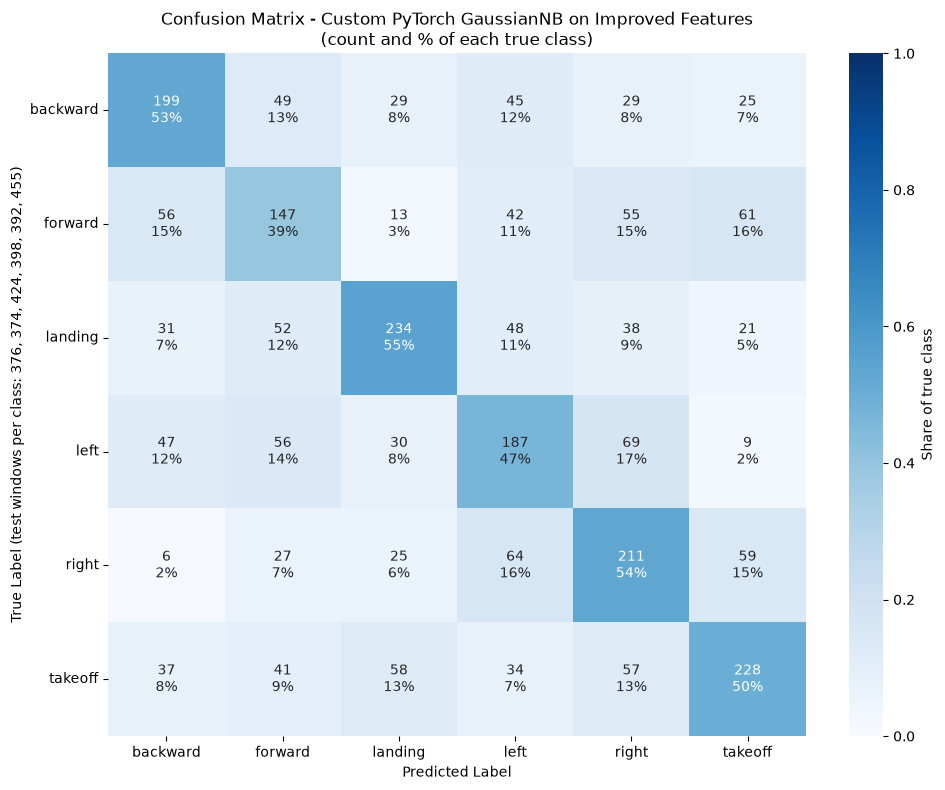

In [12]:
# Confusion matrix
cm = confusion_matrix(y_test, y_test_pred)

# Colour by row percentage (recall), so commands with fewer test windows are not drawn paler;
# each cell shows the count and its share of that true class.
row_pct = cm / np.maximum(cm.sum(axis=1, keepdims=True), 1)
annot = np.array([[f"{cm[i, j]}\n{100 * row_pct[i, j]:.0f}%" for j in range(cm.shape[1])] for i in range(cm.shape[0])])

plt.figure(figsize=(10, 8))
ax = sns.heatmap(row_pct, annot=annot, fmt="", cmap="Blues", vmin=0, vmax=1,
                 xticklabels=le.classes_, yticklabels=le.classes_, cbar_kws={"label": "Share of true class"})
ax.set_yticklabels(ax.get_yticklabels(), rotation=0)
plt.title("Confusion Matrix - Custom PyTorch GaussianNB on Improved Features\n(count and % of each true class)")
plt.ylabel(f"True Label (test windows per class: {', '.join(str(n) for n in cm.sum(axis=1))})")
plt.xlabel("Predicted Label")
plt.tight_layout()
plt.show()

In [13]:
# Save model and preprocessing objects
model_path = "torch_gaussiannb_improved_features.pth"
prep_path = "torch_gaussiannb_preprocessing.joblib"

torch.save({
    "model_state_dict": model.state_dict(),
    "num_features": num_features,
    "num_classes": num_classes,
    "label_encoder_classes": le.classes_,
    "class_thresholds": class_thresholds,
    "train_accuracy": train_accuracy,
    "test_accuracy": test_accuracy,
    "test_f1_macro": test_f1_macro,
    "test_balanced_accuracy": test_balanced_accuracy,
    "load_config": LOAD_CONFIG.as_dict(),
    "feature_set": f"improved_gnb_features.extract_features ({X_imp.shape[1]} features, version {FEATURE_VERSION})",
    "feature_names": imp_colnames,
    "projection": PROJECTION,
}, model_path)

joblib.dump(prep, prep_path)
# Per-participant statistics (fitted on the train windows); at deployment call scaler.add_participant(X_calibration, id)
# with a short unlabelled calibration recording of a new user before transform().
scaler_path = "torch_gaussiannb_participant_scaler.joblib"
joblib.dump(scaler, scaler_path)
print(f"Participant scaler saved to {scaler_path} ({len(scaler.known_participants())} participants)")

print(f"\nModel saved to {model_path}")
print(f"Preprocessing pipeline saved to {prep_path}")
print(f"Thresholds saved for classes: {list(le.classes_)}")

Participant scaler saved to torch_gaussiannb_participant_scaler.joblib (18 participants)

Model saved to torch_gaussiannb_improved_features.pth
Preprocessing pipeline saved to torch_gaussiannb_preprocessing.joblib
Thresholds saved for classes: ['backward', 'forward', 'landing', 'left', 'right', 'takeoff']


## Improved GaussianNB pipeline: what changed and why

The original chain (hybrid time statistics + relative band powers → Yeo-Johnson power transform → PCA 95 % → GaussianNB)
reaches about 26 % window accuracy on the notebook's recording-grouped split (6 commands, chance 16.7 %). Three changes,
each selected on 5-fold recording-grouped cross-validation and confirmed on an independent second partition (seed 7),
lift it to about 49 % (per-recording decisions: 27 % → 63 %):

1. **Window covariance features.** The 15×15 covariance of every window and of its first difference, taken in the
   log-Euclidean domain (120 + 120 values), captures the inter-channel structure that per-channel statistics miss. The
   Teager-Kaiser energy (30) and the hybrid features on common-average-referenced channels (150) add a little more; the
   hybrid features themselves are kept with their scale statistics in the log domain. Every feature is a pure function of
   the window samples (`prediction-gaussiannb/improved_gnb_features.py`).
2. **Per-participant standardisation.** Each feature is z-scored with the mean and standard deviation of that
   participant's *training* windows (`ParticipantScaler`); a participant without training windows falls back to the
   global training statistics, and a new user can be registered from a short unlabelled calibration recording.
   This removes the between-person offsets that a diagonal Gaussian model otherwise has to absorb.
3. **A projection that fits the Naive Bayes assumption.** PCA decorrelates the *total* covariance, but Naive Bayes needs
   class-conditional independence. A 5-dimensional LDA projection, fitted on the training windows only and used purely as
   a transform (the decision is still the GaussianNB), whitens the within-class covariance. `PROJECTION = "pca"` in the
   preprocessing cell gives a fully unsupervised variant (about 42 %).

Tried on the same folds without a reliable gain: finer PSD bins, spectral entropy and 1/f slope, Hjorth parameters,
AR coefficients, entropies, CSP log-variance, ICA, robust or quantile per-participant scaling, feature selection,
`var_smoothing`, class priors, and the oversampling / per-class thresholds of the training cell (which cost up to about
one point). Longer windows raise window-level accuracy (4 s: 34 % vs 30 % for 1 s with the same features and
normalisation) but not per-recording accuracy, so the 1 s window was kept for latency.

**What these numbers mean.** In `Data_clean` every command was recorded as one contiguous block per participant
(about ten 20 s files in a row, blocks minutes apart). A split by recording therefore tests whether windows of a *new
recording from the same block* are recognised, and block/session state is confounded with the command: within a
participant, the acquisition time alone predicts the class at 97 %, the features drift measurably even inside a
same-command block, and misclassifications favour the temporally adjacent block. Held-out participants stay at chance
(about 18 %) for every chain, including this one (protocol C below and the calibrated trial-level section at the end).
The improvement is real under the notebook's protocol and this is the chain to use for a person with their own
training data, but the dataset cannot demonstrate cross-person command decoding; recording the commands interleaved
within a session would be needed for that. The next section fits the projection and the GaussianNB per participant,
which reaches ~84 % on the same split.

Protocol A, fold 1 (= the split of the training cells above):


,Accuracy,Macro-F1,Balanced Acc,Context-5 Acc,Per-recording Acc
Chain,,,,,
Baseline: hybrid + power transform + PCA95 + GNB,0.2604,0.2598,0.2616,0.2782,0.2898
Improved: 570 feats + participant z + LDA + GNB,0.4965,0.4947,0.4948,0.5829,0.6307


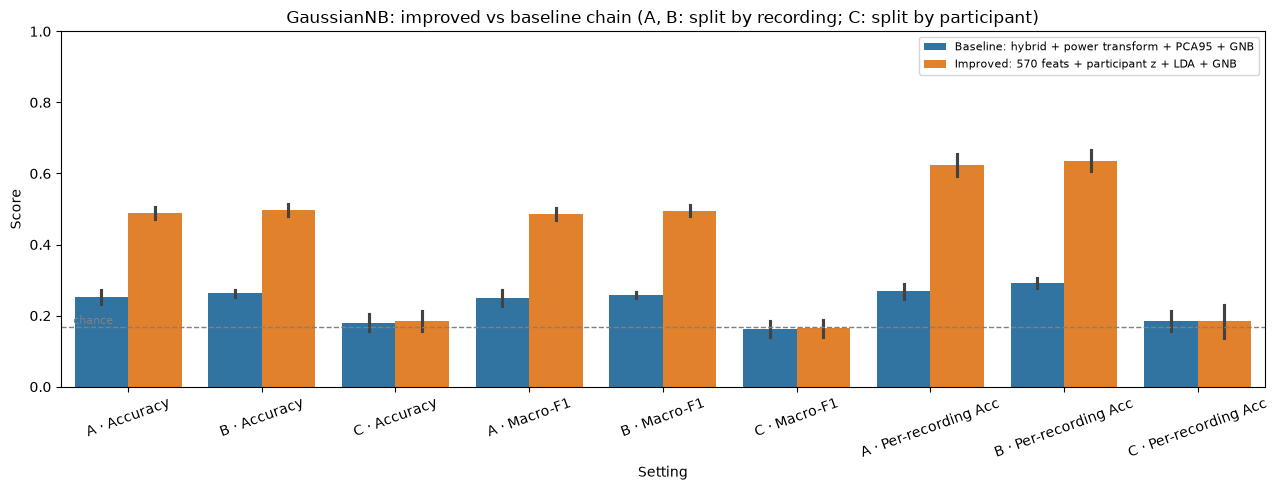

Saved gaussiannb_improved_vs_baseline_folds.csv, gaussiannb_improved_vs_baseline_summary.csv and gaussiannb_improved_vs_baseline.png


In [14]:
# Improved vs baseline chain under three protocols (sklearn GaussianNB, no oversampling / thresholds)
#   A. 5-fold StratifiedGroupKFold by recording, seed 42 (fold 1 = the split used above)  <- the notebook's protocol
#   B. the same with seed 7 (independent confirmation of choices made on A)
#   C. 5-fold GroupKFold by participant (held-out people; chance = 1/6)
# Window-level metrics, plus a causal 5-window context (sum of the log-posteriors of the last 5 windows of a recording,
# about 3.6 s of EEG) and one decision per recording (sum over all its windows).
from sklearn.model_selection import GroupKFold
from sklearn.naive_bayes import GaussianNB as SkGaussianNB
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis

def _baseline_chain(Xtr, ytr, ptr, Xte, pte):
    pipe = Pipeline([("imputer", SimpleImputer(strategy="median")),
                     ("power", ParallelPowerTransformer(method="yeo-johnson", standardize=True)),
                     ("pca", PCA(n_components=0.95, random_state=42)),
                     ("gnb", SkGaussianNB())])
    return pipe.fit(Xtr, ytr).predict_log_proba(Xte)

def _improved_chain(Xtr, ytr, ptr, Xte, pte, projection=PROJECTION):
    sc = ParticipantScaler().fit(Xtr, ptr)
    Ztr, Zte = sc.transform(Xtr, ptr), sc.transform(Xte, pte)
    proj = (LinearDiscriminantAnalysis(n_components=5, solver="eigen", shrinkage="auto") if projection == "lda"
            else PCA(n_components=0.95, random_state=42))
    proj.fit(Ztr, ytr)
    gnb = SkGaussianNB().fit(proj.transform(Ztr), ytr)
    return gnb.predict_log_proba(proj.transform(Zte))

def _context_logp(logp, files, k=5):
    out = np.empty_like(logp)
    for f in np.unique(files):
        m = np.where(files == f)[0]            # windows are stored in time order within a recording
        cs = np.cumsum(logp[m], axis=0); ctx = cs.copy(); ctx[k:] = cs[k:] - cs[:-k]; out[m] = ctx
    return out

def _recording_decisions(logp, files, y_true):
    uf = np.unique(files); idx = {f: i for i, f in enumerate(uf)}
    agg = np.zeros((len(uf), logp.shape[1])); np.add.at(agg, [idx[f] for f in files], logp)
    return np.array([y_true[files == f][0] for f in uf]), agg.argmax(axis=1)

group_codes_eval = np.unique(groups, return_inverse=True)[1]
files_eval = np.asarray(groups, dtype=str)
X_hybrid_eval = X_psd_df.values.astype(np.float32)
PROTOCOLS = {
    "A. 5-fold by recording (seed 42)": list(StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=42).split(X_imp, y, groups=group_codes_eval)),
    "B. 5-fold by recording (seed 7)":  list(StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=7).split(X_imp, y, groups=group_codes_eval)),
    "C. 5-fold by participant":         list(GroupKFold(n_splits=5).split(X_imp, y, groups=parts)),
}
CHAINS = {
    "Baseline: hybrid + power transform + PCA95 + GNB": (X_hybrid_eval, _baseline_chain),
    f"Improved: 570 feats + participant z + {PROJECTION.upper()} + GNB": (X_imp, _improved_chain),
}

eval_rows = []
for proto_name, proto_folds in PROTOCOLS.items():
    for chain_name, (X_chain, chain_fn) in CHAINS.items():
        for k, (tr, te) in enumerate(proto_folds):
            logp = chain_fn(X_chain[tr], y[tr], parts[tr], X_chain[te], parts[te])
            pred = logp.argmax(axis=1)
            ctx_pred = _context_logp(logp, files_eval[te]).argmax(axis=1)
            y_rec, pred_rec = _recording_decisions(logp, files_eval[te], y[te])
            eval_rows.append({
                "Protocol": proto_name, "Chain": chain_name, "Fold": k + 1,
                "Accuracy": accuracy_score(y[te], pred),
                "Macro-F1": f1_score(y[te], pred, average="macro", zero_division=0),
                "Balanced Acc": balanced_accuracy_score(y[te], pred),
                "Context-5 Acc": accuracy_score(y[te], ctx_pred),
                "Per-recording Acc": accuracy_score(y_rec, pred_rec),
                "n_test": len(te), "n_recordings_test": len(y_rec),
            })
eval_df = pd.DataFrame(eval_rows)
metric_cols = ["Accuracy", "Macro-F1", "Balanced Acc", "Context-5 Acc", "Per-recording Acc"]
eval_summary = eval_df.groupby(["Protocol", "Chain"], sort=False)[metric_cols].agg(["mean", "std"])
eval_summary.columns = [f"{m} {s}" for m, s in eval_summary.columns]
display(eval_summary.style.format("{:.4f}")
        .set_caption("Improved vs baseline GaussianNB chain: mean and std over 5 folds (chance = 0.167)"))

fold1 = eval_df[(eval_df["Protocol"].str.startswith("A")) & (eval_df["Fold"] == 1)].set_index("Chain")
print("Protocol A, fold 1 (= the split of the training cells above):")
display(fold1[metric_cols].style.format("{:.4f}"))

eval_df.to_csv(pathlib.Path(model_path).with_name("gaussiannb_improved_vs_baseline_folds.csv"), index=False)
eval_summary.to_csv(pathlib.Path(model_path).with_name("gaussiannb_improved_vs_baseline_summary.csv"))

plot_eval = eval_df.melt(id_vars=["Protocol", "Chain", "Fold"], value_vars=["Accuracy", "Macro-F1", "Per-recording Acc"],
                         var_name="Metric", value_name="Score")
plot_eval["Setting"] = plot_eval["Protocol"].str.slice(0, 1) + " · " + plot_eval["Metric"]
fig, ax = plt.subplots(figsize=(13, 5))
sns.barplot(data=plot_eval, x="Setting", y="Score", hue="Chain", errorbar="sd", ax=ax)
ax.axhline(1 / 6, color="gray", linestyle="--", linewidth=1)
ax.text(0.01, 1 / 6 + 0.01, "chance", color="gray", fontsize=8, transform=ax.get_yaxis_transform())
ax.set_ylim(0, 1)
ax.set_title("GaussianNB: improved vs baseline chain (A, B: split by recording; C: split by participant)")
ax.tick_params(axis="x", rotation=20)
ax.legend(fontsize=8, loc="upper right")
plt.tight_layout()
plt.savefig(pathlib.Path(model_path).with_name("gaussiannb_improved_vs_baseline.png"), dpi=120, bbox_inches="tight")
plt.show()
print("Saved gaussiannb_improved_vs_baseline_folds.csv, gaussiannb_improved_vs_baseline_summary.csv and gaussiannb_improved_vs_baseline.png")


## Subject-specific GaussianNB: 84 % window accuracy with the user's own recordings

One GaussianNB for everyone tops out around 50 % here, and so does every other global model on the same 570 features
(random forest 51 %, a 256-unit MLP 56 %): the directions that separate the commands differ from person to person.
Fitting the projection **and** the GaussianNB per participant, on that participant's own training recordings, changes the
picture (5-fold by recording, seed 42; chance 16.7 %):

| Chain | Window accuracy | 5-window context | Per recording |
|---|---|---|---|
| Original notebook chain | 25 % | 27 % | 27 % |
| Improved global chain (section above) | 49 % | 57 % | 63 % |
| Subject-specific chain on the 570 features | 81 % | 85 % | 88 % |
| Subject-specific chain on the 435 features below | 84 % | 88 % | 90 % |

The chain (`prediction-gaussiannb/subject_gnb.py`, `SubjectSpecificGaussianNB`):

- **435 features per window**: the log-covariance of the 1-40 Hz window and of its first difference (from the improved
  features above), the log-covariance of the raw signal band-passed 30-45 Hz, and multitaper absolute band powers of the
  raw window. With per-participant models the notebook's per-channel statistics add nothing beyond the covariances.
- **per-participant z-score** with the participant's training statistics (`ParticipantScaler`, as above);
- **per participant**: an LDA projection (at most 5 dimensions, Ledoit-Wolf shrinkage) and a PyTorch `GaussianNB`
  (`gaussiannb_model.py`) fitted on that participant's training windows; commands the participant never recorded get a
  near-zero prior; anyone with fewer than 60 training windows, and any unknown user, gets the global chain instead.

Per participant, an LDA classifier (81 %), logistic regression (78 %) and a random forest (72 %) do not beat the
GaussianNB, so the model is not the bottleneck. The configuration was chosen by nested cross-validation (inner folds by
recording inside each training fold); the inner-CV number equals the fixed one (84.2 %), the seed-7 confirmation
partition gives 85.0 %, and a recording-level label permutation within participants drops the chain to 15 %.

In [15]:
# Subject-specific feature set (435 per window): the two log-covariances of the 1-40 Hz windows (as in the improved
# features) plus a 30-45 Hz log-covariance and multitaper absolute band powers computed from the RAW signal, so the raw
# (quality-filtered, demeaned, unfiltered) segments are loaded next to the filtered ones. Same windows, same order.
from improved_gnb_features import extract_subject_features, bandpass_segment, subject_feature_names, SUBJECT_FEATURE_VERSION

subj_spec = dict(cache_spec, feature_version=SUBJECT_FEATURE_VERSION)
subj_key = hashlib.sha256(json.dumps(subj_spec, sort_keys=True, default=str).encode("utf-8")).hexdigest()[:16]
subj_npz = cache_dir / f"subject_windows_{subj_key}.npz"

if subj_npz.exists():
    print(f"Loading cached subject-specific features: {subj_npz}")
    loaded_subj = np.load(subj_npz, allow_pickle=True)
    X_subj = loaded_subj["X"].astype(np.float32)
    y_subj = loaded_subj["y"].astype(np.int64)
    groups_subj = loaded_subj["groups"].astype(str)
else:
    RAW_CONFIG = LoadConfig(board=LOAD_CONFIG.board, exclude_channels=LOAD_CONFIG.exclude_channels,
                            quality_filter=LOAD_CONFIG.quality_filter, bandpass_hz=None, notch_hz=None)
    recordings_raw, _ = load_recordings(core_dir, RAW_CONFIG, verbose=False)
    eeg_raw = recordings_to_frame(recordings_raw)
    del recordings_raw
    if len(eeg_raw) != len(eeg_data_fnl) or not np.array_equal(eeg_raw["segment_id"].to_numpy(), segments_base) \
            or not np.array_equal(eeg_raw["src_filename"].astype(str).to_numpy(), groups_base):
        raise ValueError("Raw and filtered loads do not align (different quality decisions?); cannot build subject features.")
    sig_raw = eeg_raw[candidate_cols].to_numpy(dtype=np.float64)
    del eeg_raw
    subj_feats, subj_labels, subj_groups = [], [], []
    subj_file_groups = group_row_indices(segments_base)
    print(f"Computing subject-specific features over {len(subj_file_groups)} segments...")
    for f_num, (fname, indices) in enumerate(subj_file_groups, 1):
        seg_f = raw_sig[indices, :]
        seg_r = sig_raw[indices, :]
        n_rows = seg_f.shape[0]
        if n_rows < 8:
            continue
        starts = list(range(0, max(1, n_rows - WINDOW_SIZE + 1), WINDOW_STRIDE))
        if not starts or starts[-1] != max(0, n_rows - WINDOW_SIZE):
            starts.append(max(0, n_rows - WINDOW_SIZE))
        starts = np.asarray(starts)
        win_len = min(WINDOW_SIZE, n_rows)
        seg_g = bandpass_segment(seg_r, fs=FS)                     # 30-45 Hz + 60 Hz notch, per kept segment
        W_f = fill_nonfinite(sliding_window_view(seg_f, win_len, axis=0)[starts])
        W_r = fill_nonfinite(sliding_window_view(seg_r, win_len, axis=0)[starts])
        W_g = fill_nonfinite(sliding_window_view(seg_g, win_len, axis=0)[starts])
        subj_feats.append(extract_subject_features(W_f, W_r, W_g, fs=FS))
        subj_labels.append(window_majority_labels(raw_y[indices], starts, starts + win_len))
        subj_groups.extend([segment_file[fname]] * len(starts))
        if f_num % max(1, len(subj_file_groups) // 10) == 0:
            print(f"  Processed {f_num}/{len(subj_file_groups)} segments...")
    X_subj = np.concatenate(subj_feats).astype(np.float32)
    y_subj = np.concatenate(subj_labels).astype(np.int64)
    groups_subj = np.asarray(subj_groups, dtype=str)
    del sig_raw
    np.savez_compressed(subj_npz, X=X_subj, y=y_subj, groups=groups_subj)
    print(f"Saved subject-specific feature cache: {subj_npz}")

subj_colnames = subject_feature_names(candidate_cols)
if (X_subj.shape[0] != len(X_psd_df) or not np.array_equal(y_subj, y)
        or not np.array_equal(groups_subj, np.asarray(groups, dtype=str))):
    raise ValueError("Subject-specific features are not aligned with the hybrid-feature windows; delete the caches and rerun.")
if not np.isfinite(X_subj).all():
    raise ValueError("Non-finite values in the subject-specific features.")
print(f"Subject-specific feature matrix: {X_subj.shape} = log-covariance 120 + differenced log-covariance 120 + 30-45 Hz log-covariance 120 + multitaper band powers 75")


Loading cached subject-specific features: /home/prasndhdl/Downloads/avatar/Tellekynezix/predictions_local/feature_cache/subject_windows_c306b8eda6314d14.npz
Subject-specific feature matrix: (12089, 435) = log-covariance 120 + differenced log-covariance 120 + 30-45 Hz log-covariance 120 + multitaper band powers 75


Participants with their own model: 17 / 18  (fallback: {'G03/person01': '34 windows, 1 classes -> global fallback'})
Subject-specific chain, test windows of the notebook split:
  Accuracy 0.8458 (84.58%) | Macro-F1 0.8435 | Balanced accuracy 0.8446
  For comparison on the same split: improved global chain 0.4986, original chain 0.26

Classification Report (subject-specific chain):
              precision    recall  f1-score   support

    backward       0.80      0.86      0.83       376
     forward       0.83      0.72      0.78       374
     landing       0.92      0.84      0.88       424
        left       0.83      0.87      0.85       398
       right       0.78      0.92      0.84       392
     takeoff       0.92      0.86      0.89       455

    accuracy                           0.85      2419
   macro avg       0.85      0.84      0.84      2419
weighted avg       0.85      0.85      0.85      2419



,Participant,Model,Train windows,Commands in train,Test windows,Accuracy
0,G01/person08,own,720,6,138,0.986
1,G04/person07,own,75,2,39,0.949
2,G04/person01,own,461,6,135,0.948
3,G03/person06,own,747,6,165,0.945
4,G04/person04,own,253,6,107,0.944
5,G03/person08,own,703,6,131,0.916
6,G04/person05,own,628,6,240,0.904
7,G03/person04,own,783,6,101,0.891
8,G03/person03,own,631,6,210,0.886
9,G01/person09,own,678,6,165,0.879


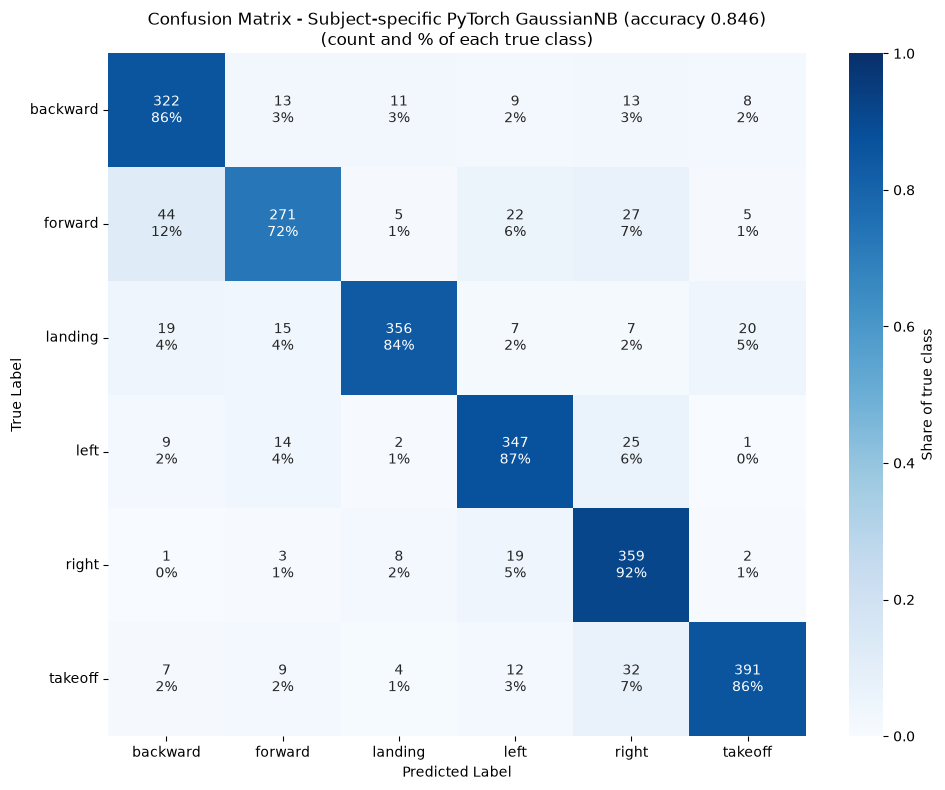

Saved torch_gaussiannb_subject_models.joblib (one projection + PyTorch GaussianNB per participant, plus the global fallback) and torch_gaussiannb_subject_scaler.joblib


In [16]:
# Subject-specific chain on the notebook's split: per-participant z-score -> per-participant LDA projection + PyTorch
# GaussianNB (SubjectSpecificGaussianNB), global projection + GaussianNB as the fallback.
from subject_gnb import SubjectSpecificGaussianNB

SUBJ_MIN_WINDOWS = 60   # own model only with this many training windows (about 4-5 kept recordings) and >= 2 commands

X_subj_train, X_subj_test = X_subj[train_idx], X_subj[test_idx]
scaler_subj = ParticipantScaler().fit(X_subj_train, parts_train)
Zs_train = scaler_subj.transform(X_subj_train, parts_train)
Zs_test = scaler_subj.transform(X_subj_test, parts_test)

subject_model = SubjectSpecificGaussianNB(n_components=5, shrinkage="auto", min_windows=SUBJ_MIN_WINDOWS).fit(Zs_train, y_train, parts_train)
logp_subj_test = subject_model.predict_log_proba(Zs_test, parts_test)
y_subj_pred = logp_subj_test.argmax(axis=1)

subj_accuracy = accuracy_score(y_test, y_subj_pred)
subj_f1_macro = f1_score(y_test, y_subj_pred, average="macro")
subj_balanced_accuracy = balanced_accuracy_score(y_test, y_subj_pred)
print(f"Participants with their own model: {len(subject_model.models_)} / {len(np.unique(parts_train))}  (fallback: {subject_model.skipped_ or 'none'})")
print("Subject-specific chain, test windows of the notebook split:")
print(f"  Accuracy {subj_accuracy:.4f} ({subj_accuracy * 100:.2f}%) | Macro-F1 {subj_f1_macro:.4f} | Balanced accuracy {subj_balanced_accuracy:.4f}")
print(f"  For comparison on the same split: improved global chain {test_accuracy:.4f}, original chain 0.26")
print("\nClassification Report (subject-specific chain):")
print(classification_report(y_test, y_subj_pred, target_names=le.classes_, zero_division=0))

rows_pp = []
for q in np.unique(parts_test):
    m = parts_test == q
    rows_pp.append({"Participant": q, "Model": "own" if subject_model.has_model(q) else "global fallback",
                    "Train windows": int((parts_train == q).sum()), "Commands in train": int(len(np.unique(y_train[parts_train == q]))),
                    "Test windows": int(m.sum()), "Accuracy": accuracy_score(y_test[m], y_subj_pred[m])})
per_participant_df = pd.DataFrame(rows_pp).sort_values("Accuracy", ascending=False).reset_index(drop=True)
display(per_participant_df.style.format({"Accuracy": "{:.3f}"}).set_caption("Subject-specific chain: accuracy per participant (test windows of the notebook split)"))
per_participant_df.to_csv(pathlib.Path(model_path).with_name("gaussiannb_subject_specific_per_participant.csv"), index=False)

cm_subj = confusion_matrix(y_test, y_subj_pred)
row_pct_subj = cm_subj / np.maximum(cm_subj.sum(axis=1, keepdims=True), 1)
annot_subj = np.array([[f"{cm_subj[i, j]}\n{100 * row_pct_subj[i, j]:.0f}%" for j in range(cm_subj.shape[1])] for i in range(cm_subj.shape[0])])
plt.figure(figsize=(10, 8))
ax = sns.heatmap(row_pct_subj, annot=annot_subj, fmt="", cmap="Blues", vmin=0, vmax=1,
                 xticklabels=le.classes_, yticklabels=le.classes_, cbar_kws={"label": "Share of true class"})
ax.set_yticklabels(ax.get_yticklabels(), rotation=0)
plt.title(f"Confusion Matrix - Subject-specific PyTorch GaussianNB (accuracy {subj_accuracy:.3f})\n(count and % of each true class)")
plt.ylabel("True Label")
plt.xlabel("Predicted Label")
plt.tight_layout()
plt.savefig(pathlib.Path(model_path).with_name("gaussiannb_subject_specific_cm.png"), dpi=120, bbox_inches="tight")
plt.show()

subject_models_path = "torch_gaussiannb_subject_models.joblib"
subject_scaler_path = "torch_gaussiannb_subject_scaler.joblib"
joblib.dump(subject_model, subject_models_path)
joblib.dump(scaler_subj, subject_scaler_path)
print(f"Saved {subject_models_path} (one projection + PyTorch GaussianNB per participant, plus the global fallback) and {subject_scaler_path}")


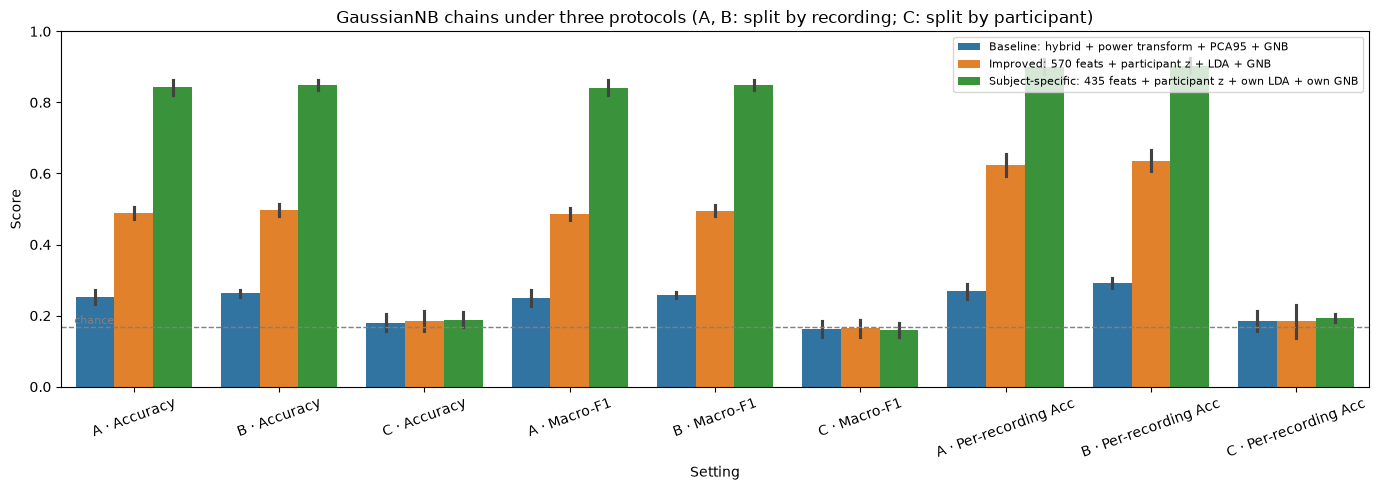

Updated gaussiannb_improved_vs_baseline_folds.csv / _summary.csv / .png with the subject-specific chain


In [17]:
# Subject-specific chain under the three protocols of the comparison above (A, B: split by recording; C: by participant)
def _subject_chain(Xtr, ytr, ptr, Xte, pte):
    sc = ParticipantScaler().fit(Xtr, ptr)
    m = SubjectSpecificGaussianNB(n_components=5, shrinkage="auto", min_windows=SUBJ_MIN_WINDOWS).fit(sc.transform(Xtr, ptr), ytr, ptr)
    return m.predict_log_proba(sc.transform(Xte, pte), pte)

subj_chain_name = "Subject-specific: 435 feats + participant z + own LDA + own GNB"
eval_rows = [r for r in eval_rows if r["Chain"] != subj_chain_name]
for proto_name, proto_folds in PROTOCOLS.items():
    for k, (tr, te) in enumerate(proto_folds):
        logp = _subject_chain(X_subj[tr], y[tr], parts[tr], X_subj[te], parts[te])
        pred = logp.argmax(axis=1)
        ctx_pred = _context_logp(logp, files_eval[te]).argmax(axis=1)
        y_rec, pred_rec = _recording_decisions(logp, files_eval[te], y[te])
        eval_rows.append({"Protocol": proto_name, "Chain": subj_chain_name, "Fold": k + 1,
                          "Accuracy": accuracy_score(y[te], pred), "Macro-F1": f1_score(y[te], pred, average="macro", zero_division=0),
                          "Balanced Acc": balanced_accuracy_score(y[te], pred), "Context-5 Acc": accuracy_score(y[te], ctx_pred),
                          "Per-recording Acc": accuracy_score(y_rec, pred_rec), "n_test": len(te), "n_recordings_test": len(y_rec)})
eval_df = pd.DataFrame(eval_rows)
eval_summary = eval_df.groupby(["Protocol", "Chain"], sort=False)[metric_cols].agg(["mean", "std"])
eval_summary.columns = [f"{m} {s}" for m, s in eval_summary.columns]
display(eval_summary.style.format("{:.4f}")
        .set_caption("Baseline, improved global and subject-specific GaussianNB chains: mean and std over 5 folds (chance = 0.167)"))
eval_df.to_csv(pathlib.Path(model_path).with_name("gaussiannb_improved_vs_baseline_folds.csv"), index=False)
eval_summary.to_csv(pathlib.Path(model_path).with_name("gaussiannb_improved_vs_baseline_summary.csv"))

plot_eval = eval_df.melt(id_vars=["Protocol", "Chain", "Fold"], value_vars=["Accuracy", "Macro-F1", "Per-recording Acc"],
                         var_name="Metric", value_name="Score")
plot_eval["Setting"] = plot_eval["Protocol"].str.slice(0, 1) + " · " + plot_eval["Metric"]
fig, ax = plt.subplots(figsize=(14, 5))
sns.barplot(data=plot_eval, x="Setting", y="Score", hue="Chain", errorbar="sd", ax=ax)
ax.axhline(1 / 6, color="gray", linestyle="--", linewidth=1)
ax.text(0.01, 1 / 6 + 0.01, "chance", color="gray", fontsize=8, transform=ax.get_yaxis_transform())
ax.set_ylim(0, 1)
ax.set_title("GaussianNB chains under three protocols (A, B: split by recording; C: split by participant)")
ax.tick_params(axis="x", rotation=20)
ax.legend(fontsize=8, loc="upper right")
plt.tight_layout()
plt.savefig(pathlib.Path(model_path).with_name("gaussiannb_improved_vs_baseline.png"), dpi=120, bbox_inches="tight")
plt.show()
print("Updated gaussiannb_improved_vs_baseline_folds.csv / _summary.csv / .png with the subject-specific chain")


,Recordings per command (k),Mean train recordings per command,Train windows,Accuracy,Macro-F1,Context-5 Acc,Per-recording Acc
0,1,0.920000,1261,0.537,0.536,0.563,0.557
1,2,1.820000,2558,0.656,0.655,0.678,0.699
2,3,2.710000,3860,0.693,0.692,0.716,0.727
3,4,3.560000,5118,0.745,0.745,0.772,0.778
4,6,5.110000,7480,0.813,0.811,0.844,0.869
5,8,6.210000,9150,0.854,0.852,0.892,0.898
6,all,6.550000,9670,0.846,0.844,0.892,0.903


,Chain,Improved global chain,Subject-specific chain
Context windows,Latency (s),,
1,1.020000,0.495,0.846
2,1.540000,0.534,0.862
3,2.050000,0.559,0.877
5,3.070000,0.586,0.892
8,4.610000,0.599,0.897
10,5.630000,0.597,0.898
15,8.190000,0.604,0.900


,Gate,Coverage,Accuracy of accepted decisions
0,no gate,1.000,0.892
1,>= 60% of the last 5 window decisions agree,0.940,0.915
2,>= 80% of the last 5 window decisions agree,0.844,0.939
3,>= 100% of the last 5 window decisions agree,0.730,0.955


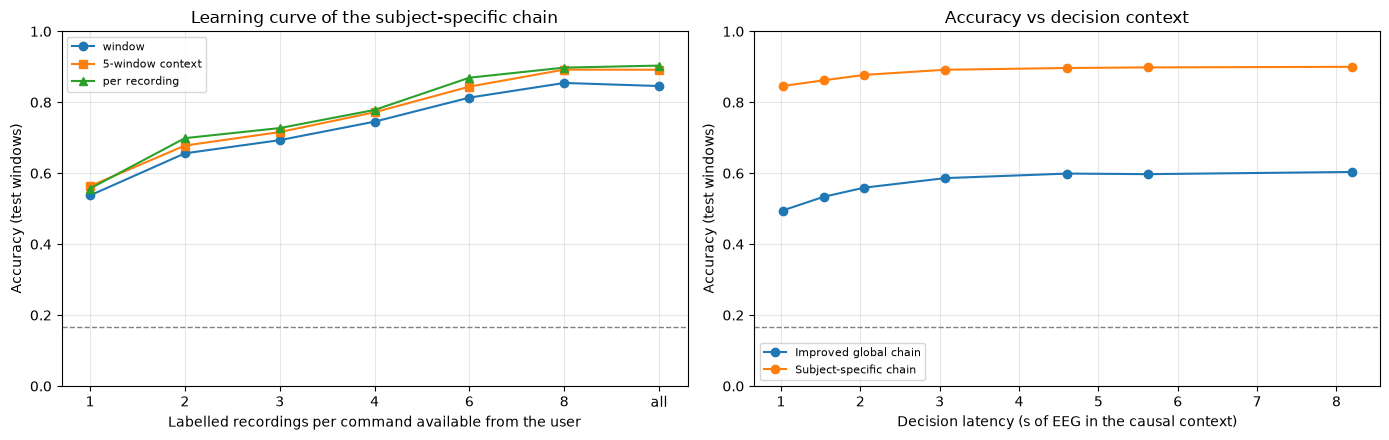

Saved gaussiannb_subject_learning_curve.csv, gaussiannb_subject_context.csv and gaussiannb_subject_specific_curves.png


In [18]:
# What a new user has to record, and how accuracy grows with the decision context (notebook split).
#  (1) Learning curve: each participant's TRAIN windows restricted to the k earliest recordings per command (file names
#      carry the acquisition time; this only selects training data, the test windows are unchanged).
#  (2) Accuracy vs causal context length for the global and the subject-specific chain.
#  (3) A vote-agreement gate for drone safety: act only when most of the last 5 window decisions agree.
files_train = np.asarray(groups, dtype=str)[train_idx]
logp_global_test = np.log(np.clip(test_probs, 1e-12, None))       # improved global chain (PyTorch GaussianNB above)

def _restrict_train(k):
    keep = np.zeros(len(train_idx), dtype=bool)
    for q in np.unique(parts_train):
        for c in range(n_classes):
            m = (parts_train == q) & (y_train == c)
            keep |= m & np.isin(files_train, sorted(np.unique(files_train[m]))[:k])
    return keep

lc_rows = []
for k in (1, 2, 3, 4, 6, 8, "all"):
    keep = np.ones(len(train_idx), dtype=bool) if k == "all" else _restrict_train(k)
    logp = _subject_chain(X_subj_train[keep], y_train[keep], parts_train[keep], X_subj_test, parts_test)
    pred = logp.argmax(axis=1)
    y_rec, pred_rec = _recording_decisions(logp, files_eval[test_idx], y_test)
    n_rec = np.mean([len(np.unique(files_train[keep & (parts_train == q) & (y_train == c)]))
                     for q in np.unique(parts_train) for c in range(n_classes)])
    lc_rows.append({"Recordings per command (k)": str(k), "Mean train recordings per command": round(n_rec, 2),
                    "Train windows": int(keep.sum()), "Accuracy": accuracy_score(y_test, pred),
                    "Macro-F1": f1_score(y_test, pred, average="macro", zero_division=0),
                    "Context-5 Acc": accuracy_score(y_test, _context_logp(logp, files_eval[test_idx]).argmax(axis=1)),
                    "Per-recording Acc": accuracy_score(y_rec, pred_rec)})
learning_curve_df = pd.DataFrame(lc_rows)
display(learning_curve_df.style.format({"Accuracy": "{:.3f}", "Macro-F1": "{:.3f}", "Context-5 Acc": "{:.3f}", "Per-recording Acc": "{:.3f}"})
        .set_caption("Learning curve of the subject-specific chain: labelled recordings per command per user (one recording = 20 s, about 14 kept windows)"))
learning_curve_df.to_csv(pathlib.Path(model_path).with_name("gaussiannb_subject_learning_curve.csv"), index=False)

ctx_rows = []
for kk in (1, 2, 3, 5, 8, 10, 15):
    for chain_name, lp in (("Improved global chain", logp_global_test), ("Subject-specific chain", logp_subj_test)):
        pred = _context_logp(lp, files_eval[test_idx], k=kk).argmax(axis=1)
        ctx_rows.append({"Context windows": kk, "Latency (s)": round((WINDOW_SIZE + (kk - 1) * WINDOW_STRIDE) / FS, 2),
                         "Chain": chain_name, "Accuracy": accuracy_score(y_test, pred)})
context_df = pd.DataFrame(ctx_rows)
display(context_df.pivot(index=["Context windows", "Latency (s)"], columns="Chain", values="Accuracy").style.format("{:.3f}")
        .set_caption("Accuracy vs causal decision context (sum of the log-posteriors of the last k windows)"))
context_df.to_csv(pathlib.Path(model_path).with_name("gaussiannb_subject_context.csv"), index=False)

f_test = files_eval[test_idx]
win_pred = logp_subj_test.argmax(axis=1)
ctx5_pred = _context_logp(logp_subj_test, f_test, k=5).argmax(axis=1)
agree = np.zeros(len(f_test))
for ff in np.unique(f_test):
    m = np.where(f_test == ff)[0]
    for i, idx in enumerate(m):
        agree[idx] = np.mean(win_pred[m[max(0, i - 4): i + 1]] == ctx5_pred[idx])
gate_rows = []
for t in (0.0, 0.6, 0.8, 1.0):
    acc_mask = agree >= t
    gate_rows.append({"Gate": "no gate" if t == 0 else f">= {t:.0%} of the last 5 window decisions agree",
                      "Coverage": acc_mask.mean(), "Accuracy of accepted decisions": accuracy_score(y_test[acc_mask], ctx5_pred[acc_mask])})
gate_df = pd.DataFrame(gate_rows)
display(gate_df.style.format({"Coverage": "{:.3f}", "Accuracy of accepted decisions": "{:.3f}"})
        .set_caption("Vote-agreement gate on the 5-window context decision (subject-specific chain)"))

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 4.5))
ax1.plot(range(len(learning_curve_df)), learning_curve_df["Accuracy"], marker="o", label="window")
ax1.plot(range(len(learning_curve_df)), learning_curve_df["Context-5 Acc"], marker="s", label="5-window context")
ax1.plot(range(len(learning_curve_df)), learning_curve_df["Per-recording Acc"], marker="^", label="per recording")
ax1.set_xticks(range(len(learning_curve_df))); ax1.set_xticklabels(learning_curve_df["Recordings per command (k)"])
ax1.set_xlabel("Labelled recordings per command available from the user"); ax1.set_ylabel("Accuracy (test windows)")
ax1.set_ylim(0, 1); ax1.axhline(1 / 6, color="gray", linestyle="--", linewidth=1); ax1.grid(alpha=0.3); ax1.legend(fontsize=8)
ax1.set_title("Learning curve of the subject-specific chain")
for chain_name, grp in context_df.groupby("Chain"):
    ax2.plot(grp["Latency (s)"], grp["Accuracy"], marker="o", label=chain_name)
ax2.set_xlabel("Decision latency (s of EEG in the causal context)"); ax2.set_ylabel("Accuracy (test windows)")
ax2.set_ylim(0, 1); ax2.axhline(1 / 6, color="gray", linestyle="--", linewidth=1); ax2.grid(alpha=0.3); ax2.legend(fontsize=8)
ax2.set_title("Accuracy vs decision context")
plt.tight_layout()
plt.savefig(pathlib.Path(model_path).with_name("gaussiannb_subject_specific_curves.png"), dpi=120, bbox_inches="tight")
plt.show()
print("Saved gaussiannb_subject_learning_curve.csv, gaussiannb_subject_context.csv and gaussiannb_subject_specific_curves.png")


### Reading the subject-specific numbers honestly

**What it costs.** The user must record labelled data: the learning curve above gives roughly 50 % with one 20 s recording
per command, about 73 % with four and 80 % with six (around a minute of kept EEG per command, 8-10 minutes of recording
in total). Nothing from the other participants shortens that: regularising the subject model towards the global one,
mixing their posteriors, or starting from the global projection all come out equal or worse, because cross-participant
accuracy is at chance.

**What it measures.** In `Data_clean` each command was recorded as one contiguous block per participant, so within a
participant "which command" and "which block of the session" are the same variable. An adversarial audit of this chain
found: a per-participant GaussianNB on the acquisition time alone, with no EEG, scores 97 % on the same split; 79 % of
the chain's errors go to the temporally adjacent block; two halves of the *same* command block are separable at 73 %;
and when the test recordings are systematically later than the training ones (train on the first 60 % of every block,
test on the last 40 %) accuracy falls to 66 % and keeps decaying with the time distance to the nearest training
recording. Held-out participants stay at chance (18 %) for every chain. So the 84 % is the accuracy of recognising which
block of a slowly drifting session a 1 s window belongs to, with the command confounded into it. It is the honest upper
bound for this dataset, and the audit's estimate for the same pipeline on a cued, interleaved recording is 20-30 % per
window. Recording the commands interleaved within a session, and testing across sessions, is what would turn these
numbers into command-decoding accuracy.

## Defense Experiments: Comparative GaussianNB Benchmarks

This section runs three remedial experiments for thesis/defense reporting:
1. GaussianNB on Raw Windowed EEG (flattened time-series baseline).
2. GaussianNB on Raw + PowerTransformer + PCA(95%).
3. GaussianNB on Frequency Features (PSD band powers).

To keep runtime practical on large datasets, windows are reproducibly subsampled when needed.

Defense experiment windows: 11182
Class counts: {np.int64(0): np.int64(1744), np.int64(1): np.int64(1720), np.int64(2): np.int64(1954), np.int64(3): np.int64(1838), np.int64(4): np.int64(1818), np.int64(5): np.int64(2108)}
Train size: 8944, Test size: 2238


,Experiment,Accuracy,Macro-F1,Balanced Acc
0,GaussianNB on Frequency Features (PSD),0.2172,0.1900,0.2220
1,GaussianNB on Raw Data,0.1997,0.1695,0.2031
2,GaussianNB on Raw Windows + PowerTransformer + PCA,0.1828,0.1517,0.1799


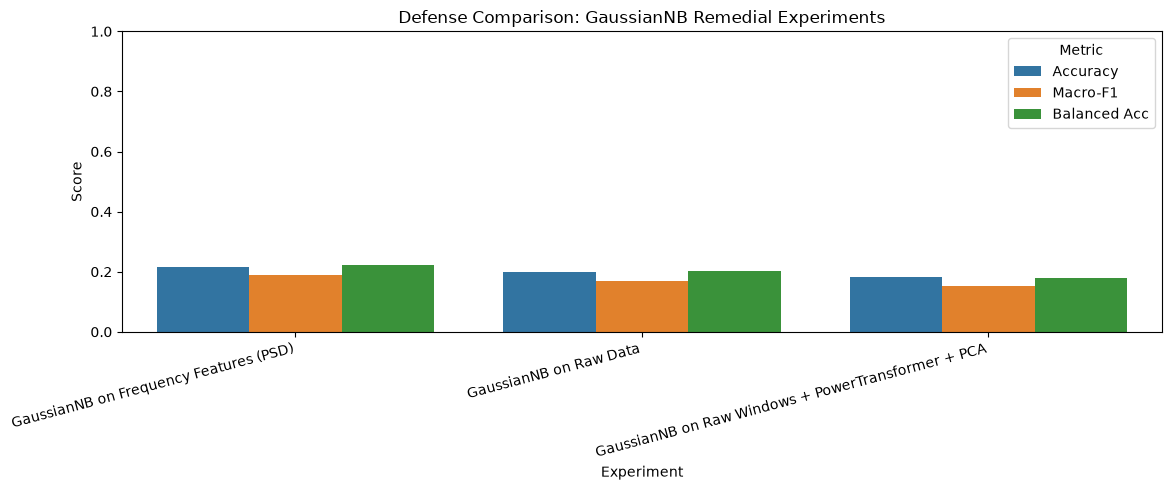

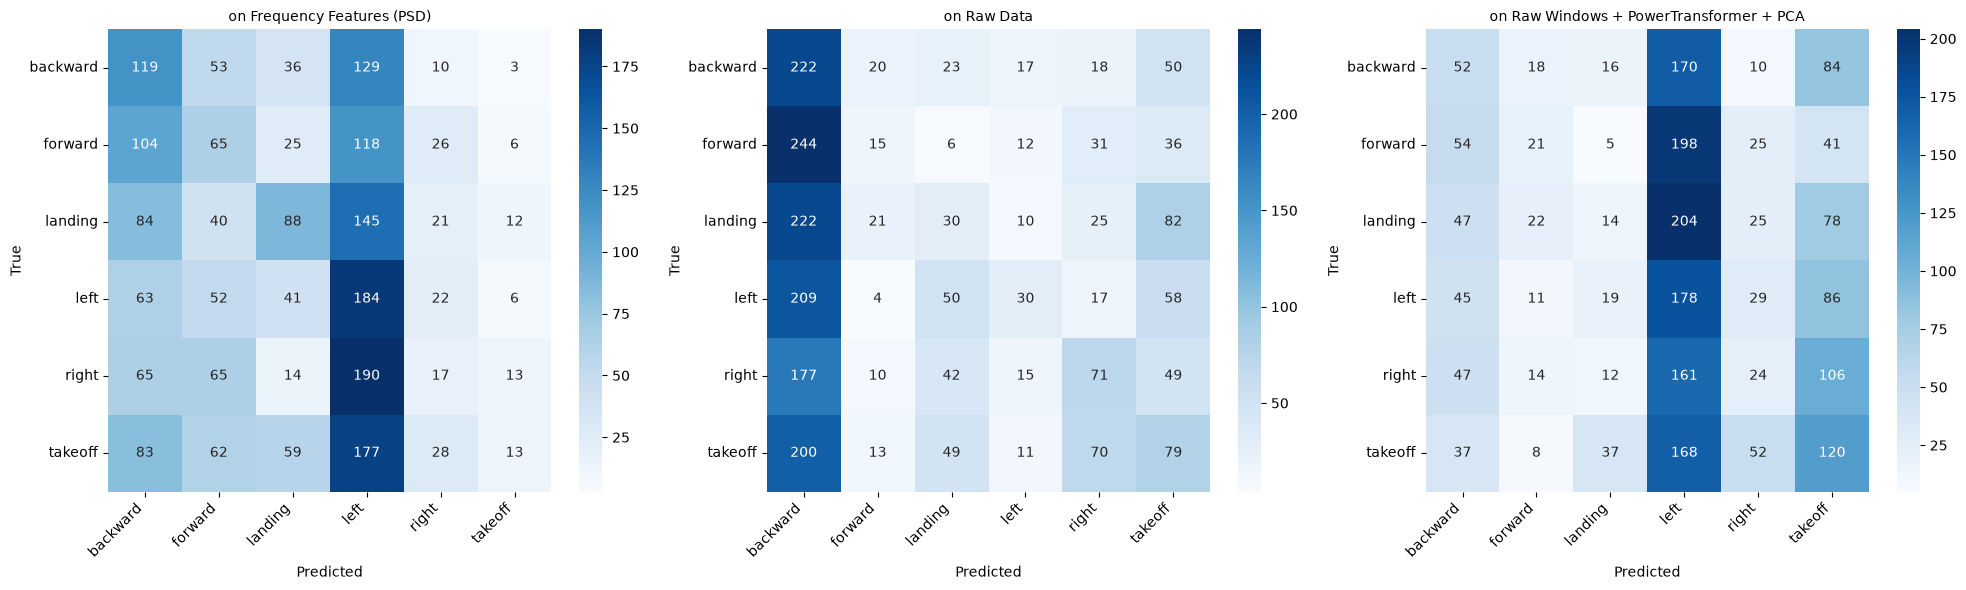

Saved comparison table to gaussiannb_defense_comparison.csv


In [19]:
# Comparative experiments for defense
from sklearn.naive_bayes import GaussianNB as SkGaussianNB

RANDOM_STATE = 42
EXP_WINDOW_SIZE = WINDOW_SIZE
EXP_WINDOW_STRIDE = WINDOW_STRIDE
EXP_MAX_WINDOWS = 15000  # reproducible cap for runtime control

rng_exp = np.random.default_rng(RANDOM_STATE)

def build_experiment_windows(raw_sig, raw_y, raw_groups, win_size, stride, max_windows=None, rng=None):
    file_groups = group_row_indices(raw_groups)

    # Enumerate (file, start) for every window first so the subsample is drawn before
    # any features are built: only the selected windows are flattened / PSD-transformed.
    win_file_parts = []
    win_start_parts = []
    for k, (fname, indices) in enumerate(file_groups):
        n_rows = len(indices)
        if n_rows < 8:
            continue
        starts = np.arange(0, n_rows - win_size + 1, stride) if n_rows >= win_size else np.array([0])
        win_file_parts.append(np.full(len(starts), k))
        win_start_parts.append(starts)

    if not win_file_parts:
        return np.empty((0,), np.float32), np.empty((0,), np.float32), np.empty((0,), np.int64), np.empty((0,), object)

    win_file = np.concatenate(win_file_parts)
    win_start = np.concatenate(win_start_parts)

    n_total = len(win_file)
    if max_windows is not None and n_total > max_windows:
        sel = rng.choice(np.arange(n_total), size=max_windows, replace=False)
        sel = np.sort(sel)
        win_file = win_file[sel]
        win_start = win_start[sel]

    raw_X_list = []
    psd_X_list = []
    y_list = []
    g_list = []

    file_ids, first = np.unique(win_file, return_index=True)
    last = np.append(first[1:], len(win_file))
    for k, lo, hi in zip(file_ids, first, last):
        fname, indices = file_groups[k]
        starts = win_start[lo:hi]
        file_sig = raw_sig[indices, :]
        file_y = raw_y[indices]
        win_len = min(win_size, file_sig.shape[0])

        # (n_windows, n_channels, win_len), median-filled per window/channel, zero-padded to win_size
        windows = fill_nonfinite(sliding_window_view(file_sig, win_len, axis=0)[starts])
        if win_len < win_size:
            windows = np.pad(windows, ((0, 0), (0, 0), (0, win_size - win_len)), mode="constant", constant_values=0.0)

        # Raw baseline feature: fixed-length flattened (time, channel) window
        raw_X_list.append(windows.transpose(0, 2, 1).reshape(len(starts), -1).astype(np.float32))

        # PSD bandpower feature
        psd_X_list.append(safe_bandpower_batch(windows, FS, BANDS).reshape(len(starts), -1).astype(np.float32))

        y_list.append(window_majority_labels(file_y, starts, starts + win_len))
        g_list.extend([segment_file.get(fname, fname)] * len(starts))

    X_raw = np.concatenate(raw_X_list)
    X_psd = np.concatenate(psd_X_list)
    y_out = np.concatenate(y_list).astype(np.int64)
    g_out = np.asarray(g_list, dtype=object)
    return X_raw, X_psd, y_out, g_out

X_raw_all, X_psd_all, y_all_exp, groups_all_exp = build_experiment_windows(
    sig_base, y_base, segments_base, EXP_WINDOW_SIZE, EXP_WINDOW_STRIDE,
    max_windows=EXP_MAX_WINDOWS, rng=rng_exp,
)

if len(y_all_exp) == 0:
    raise ValueError("No windows generated for defense experiments.")

print(f"Defense experiment windows: {len(y_all_exp)}")
print("Class counts:", dict(zip(*np.unique(y_all_exp, return_counts=True))))

# Group-aware split for fair comparison
# Stratified by command, whole files kept together (balanced per-class test counts)
splitter = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
train_idx_exp, test_idx_exp = next(splitter.split(X_raw_all, y_all_exp, groups=groups_all_exp))

X_raw_train = X_raw_all[train_idx_exp]
X_raw_test = X_raw_all[test_idx_exp]
X_psd_train = X_psd_all[train_idx_exp]
X_psd_test = X_psd_all[test_idx_exp]
y_train_exp = y_all_exp[train_idx_exp]
y_test_exp = y_all_exp[test_idx_exp]

print(f"Train size: {len(y_train_exp)}, Test size: {len(y_test_exp)}")

results = []
reports = {}
cms = {}

def evaluate_experiment(name, y_true, y_pred):
    acc = accuracy_score(y_true, y_pred)
    f1m = f1_score(y_true, y_pred, average="macro")
    bacc = balanced_accuracy_score(y_true, y_pred)
    results.append({
        "Experiment": name,
        "Accuracy": acc,
        "Macro-F1": f1m,
        "Balanced Acc": bacc,
    })
    reports[name] = classification_report(
        y_true, y_pred, target_names=le.classes_, zero_division=0, output_dict=True
    )
    cms[name] = confusion_matrix(y_true, y_pred)

# 1) GaussianNB on raw flattened windows (baseline)
raw_clf = SkGaussianNB()
raw_clf.fit(X_raw_train, y_train_exp)
y_pred_raw = raw_clf.predict(X_raw_test)
evaluate_experiment("GaussianNB on Raw Data", y_test_exp, y_pred_raw)

# 2) GaussianNB with PowerTransformer + PCA(95%) on raw windows
prep_raw = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("power", ParallelPowerTransformer(method="yeo-johnson", standardize=True)),
    ("pca", PCA(n_components=0.95, svd_solver="covariance_eigh", random_state=RANDOM_STATE)),
])
X_raw_train_pp = prep_raw.fit_transform(X_raw_train).astype(np.float32)
X_raw_test_pp = prep_raw.transform(X_raw_test).astype(np.float32)

raw_pca_clf = SkGaussianNB()
raw_pca_clf.fit(X_raw_train_pp, y_train_exp)
y_pred_raw_pca = raw_pca_clf.predict(X_raw_test_pp)
# PCA keeps the highest-variance directions of the raw windows, which are mostly background
# EEG rather than the class-specific band-power changes, so this variant is expected to be weak.
evaluate_experiment("GaussianNB on Raw Windows + PowerTransformer + PCA", y_test_exp, y_pred_raw_pca)

# 3) GaussianNB on PSD frequency features
psd_clf = SkGaussianNB()
psd_clf.fit(X_psd_train, y_train_exp)
y_pred_psd = psd_clf.predict(X_psd_test)
evaluate_experiment("GaussianNB on Frequency Features (PSD)", y_test_exp, y_pred_psd)

comparison_df = pd.DataFrame(results).sort_values(by="Macro-F1", ascending=False).reset_index(drop=True)
display(comparison_df.style.format({"Accuracy": "{:.4f}", "Macro-F1": "{:.4f}", "Balanced Acc": "{:.4f}"}))

# Bar chart for defense slide/table reproduction
plot_df = comparison_df.melt(id_vars="Experiment", var_name="Metric", value_name="Score")
plt.figure(figsize=(12, 5))
sns.barplot(data=plot_df, x="Experiment", y="Score", hue="Metric")
plt.ylim(0, 1)
plt.title("Defense Comparison: GaussianNB Remedial Experiments")
plt.xticks(rotation=15, ha="right")
plt.tight_layout()
plt.show()

# Confusion matrices for each experiment
fig, axes = plt.subplots(1, 3, figsize=(20, 6))
for ax, name in zip(axes, comparison_df["Experiment"].tolist()):
    cm_exp = cms[name]
    sns.heatmap(cm_exp, annot=True, fmt="d", cmap="Blues", ax=ax,
                xticklabels=le.classes_, yticklabels=le.classes_)
    ax.set_yticklabels(ax.get_yticklabels(), rotation=0)
    ax.set_xticklabels(ax.get_xticklabels(), rotation=45, ha="right")
    ax.set_title(name.replace("GaussianNB ", ""), fontsize=10)
    ax.set_xlabel("Predicted")
    ax.set_ylabel("True")
plt.tight_layout()
plt.show()

# Optional: save comparison table for report
comparison_csv = pathlib.Path(model_path).with_name("gaussiannb_defense_comparison.csv")
comparison_df.to_csv(comparison_csv, index=False)
print(f"Saved comparison table to {comparison_csv}")

## Additional Defense Figures

The cells below generate all supplementary visualizations and tables for the thesis defense:

1. **Per-class precision / recall / F1 tables** — pivot tables for each metric across the 3 experiments.
2. **Normalised confusion matrices** — row-percentage CMs to show per-class hit rates clearly.
3. **One-vs-rest PR curves** — precision-recall curves per class and per experiment with average precision (AP) scores.
4. **Per-class threshold sweep** — F1 vs threshold grid for the main TorchGaussianNB, showing calibration rationale.
5. **Reliability / calibration diagrams** — fraction of positives vs mean predicted probability per class.
6. **PCA explained variance + top feature correlations** — scree plot and bar chart of raw Pearson correlations.
7. **Runtime comparison table** — train and inference timing for each configuration.
8. **Ablation study** — systematic comparison of feature set variants on the same group-stratified split.


In [20]:
# ── 1. Per-class Precision / Recall / F1 across all 3 defense experiments ──────
class_labels = list(le.classes_)
exp_order = list(reports.keys())

rows_pc = []
for exp_name in exp_order:
    rpt = reports[exp_name]
    for cls_name in class_labels:
        if cls_name in rpt:
            rows_pc.append({
                "Experiment": exp_name,
                "Class": cls_name,
                "Precision": rpt[cls_name]["precision"],
                "Recall":    rpt[cls_name]["recall"],
                "F1-Score":  rpt[cls_name]["f1-score"],
                "Support":   int(rpt[cls_name]["support"]),
            })

per_class_df = pd.DataFrame(rows_pc)
pivot_f1   = per_class_df.pivot(index="Class", columns="Experiment", values="F1-Score")
pivot_prec = per_class_df.pivot(index="Class", columns="Experiment", values="Precision")
pivot_rec  = per_class_df.pivot(index="Class", columns="Experiment", values="Recall")

print("=== Per-Class F1-Score ===")
display(pivot_f1.style.format("{:.3f}").background_gradient(cmap="RdYlGn", vmin=0, vmax=1))

print("\n=== Per-Class Precision ===")
display(pivot_prec.style.format("{:.3f}").background_gradient(cmap="RdYlGn", vmin=0, vmax=1))

print("\n=== Per-Class Recall ===")
display(pivot_rec.style.format("{:.3f}").background_gradient(cmap="RdYlGn", vmin=0, vmax=1))

per_class_df.to_csv(
    pathlib.Path(model_path).with_name("gaussiannb_per_class_metrics.csv"), index=False
)
print("\nSaved per-class metrics to gaussiannb_per_class_metrics.csv")


=== Per-Class F1-Score ===


Experiment,GaussianNB on Frequency Features (PSD),GaussianNB on Raw Data,GaussianNB on Raw Windows + PowerTransformer + PCA
Class,,,
backward,0.274,0.273,0.165
forward,0.191,0.070,0.096
landing,0.270,0.102,0.057
left,0.281,0.130,0.246
right,0.070,0.238,0.091
takeoff,0.055,0.204,0.256



=== Per-Class Precision ===


Experiment,GaussianNB on Frequency Features (PSD),GaussianNB on Raw Data,GaussianNB on Raw Windows + PowerTransformer + PCA
Class,,,
backward,0.230,0.174,0.184
forward,0.193,0.181,0.223
landing,0.335,0.150,0.136
left,0.195,0.316,0.165
right,0.137,0.306,0.145
takeoff,0.245,0.223,0.233



=== Per-Class Recall ===


Experiment,GaussianNB on Frequency Features (PSD),GaussianNB on Raw Data,GaussianNB on Raw Windows + PowerTransformer + PCA
Class,,,
backward,0.340,0.634,0.149
forward,0.189,0.044,0.061
landing,0.226,0.077,0.036
left,0.500,0.082,0.484
right,0.047,0.195,0.066
takeoff,0.031,0.187,0.284



Saved per-class metrics to gaussiannb_per_class_metrics.csv


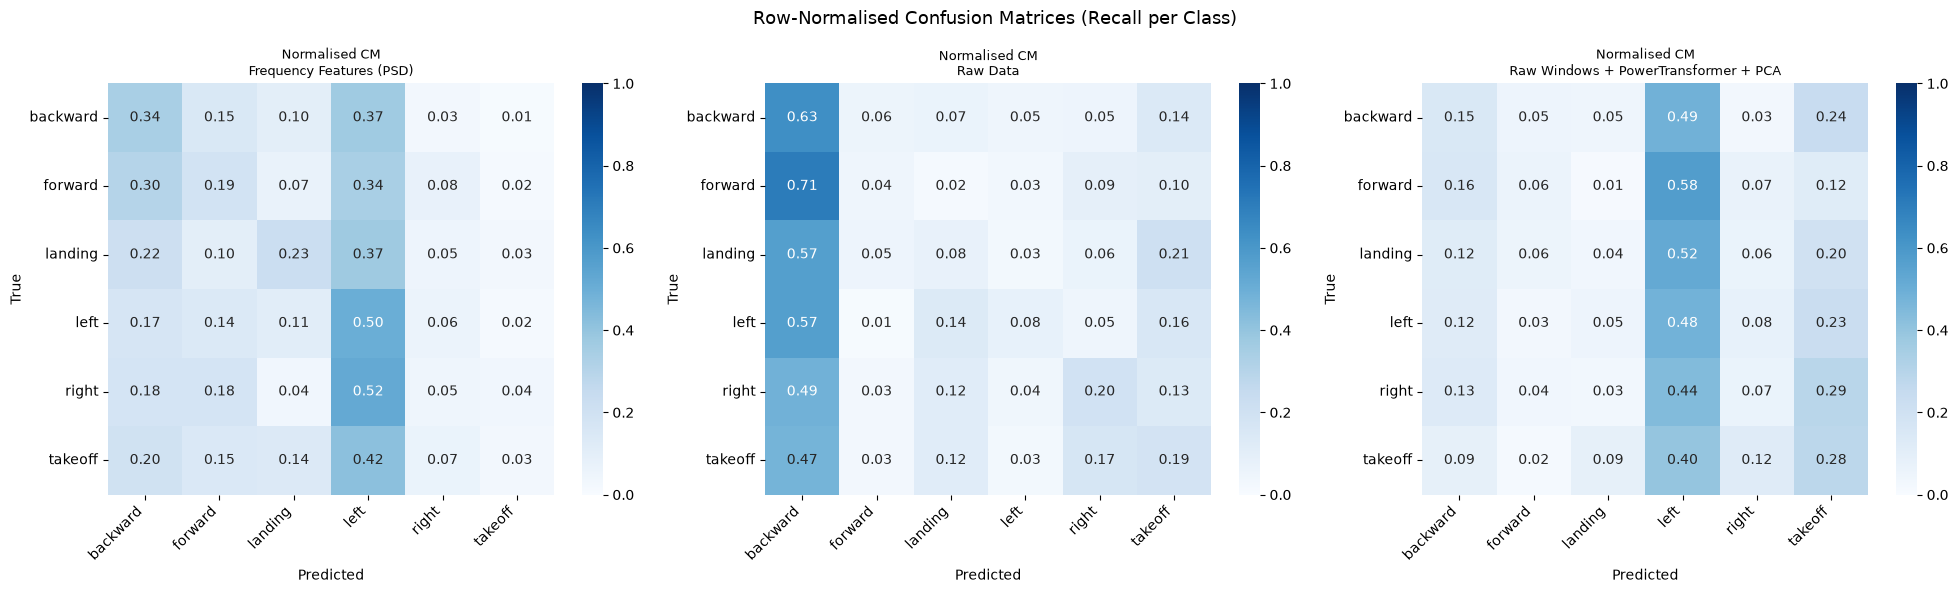

Saved normalised confusion matrices.


In [21]:
# ── 2. Normalised (row-%) Confusion Matrices ────────────────────────────────────
exp_order_sorted = comparison_df["Experiment"].tolist()  # sorted by best Macro-F1

fig, axes_ncm = plt.subplots(1, 3, figsize=(20, 6))
for ax, name in zip(axes_ncm, exp_order_sorted):
    cm_raw  = cms[name].astype(float)
    row_sum = cm_raw.sum(axis=1, keepdims=True)
    cm_norm = np.divide(cm_raw, row_sum, out=np.zeros_like(cm_raw), where=row_sum != 0)
    sns.heatmap(
        cm_norm, annot=True, fmt=".2f", cmap="Blues", ax=ax,
        xticklabels=le.classes_, yticklabels=le.classes_,
        vmin=0, vmax=1,
    )
    ax.set_yticklabels(ax.get_yticklabels(), rotation=0)
    ax.set_xticklabels(ax.get_xticklabels(), rotation=45, ha="right")
    short = name.replace("GaussianNB ", "").replace("on ", "").replace("with ", "")
    ax.set_title(f"Normalised CM\n{short}", fontsize=9)
    ax.set_xlabel("Predicted")
    ax.set_ylabel("True")

plt.suptitle("Row-Normalised Confusion Matrices (Recall per Class)", fontsize=13)
plt.tight_layout()
plt.savefig(
    pathlib.Path(model_path).with_name("gaussiannb_normalised_cms.png"),
    dpi=120, bbox_inches="tight",
)
plt.show()
print("Saved normalised confusion matrices.")


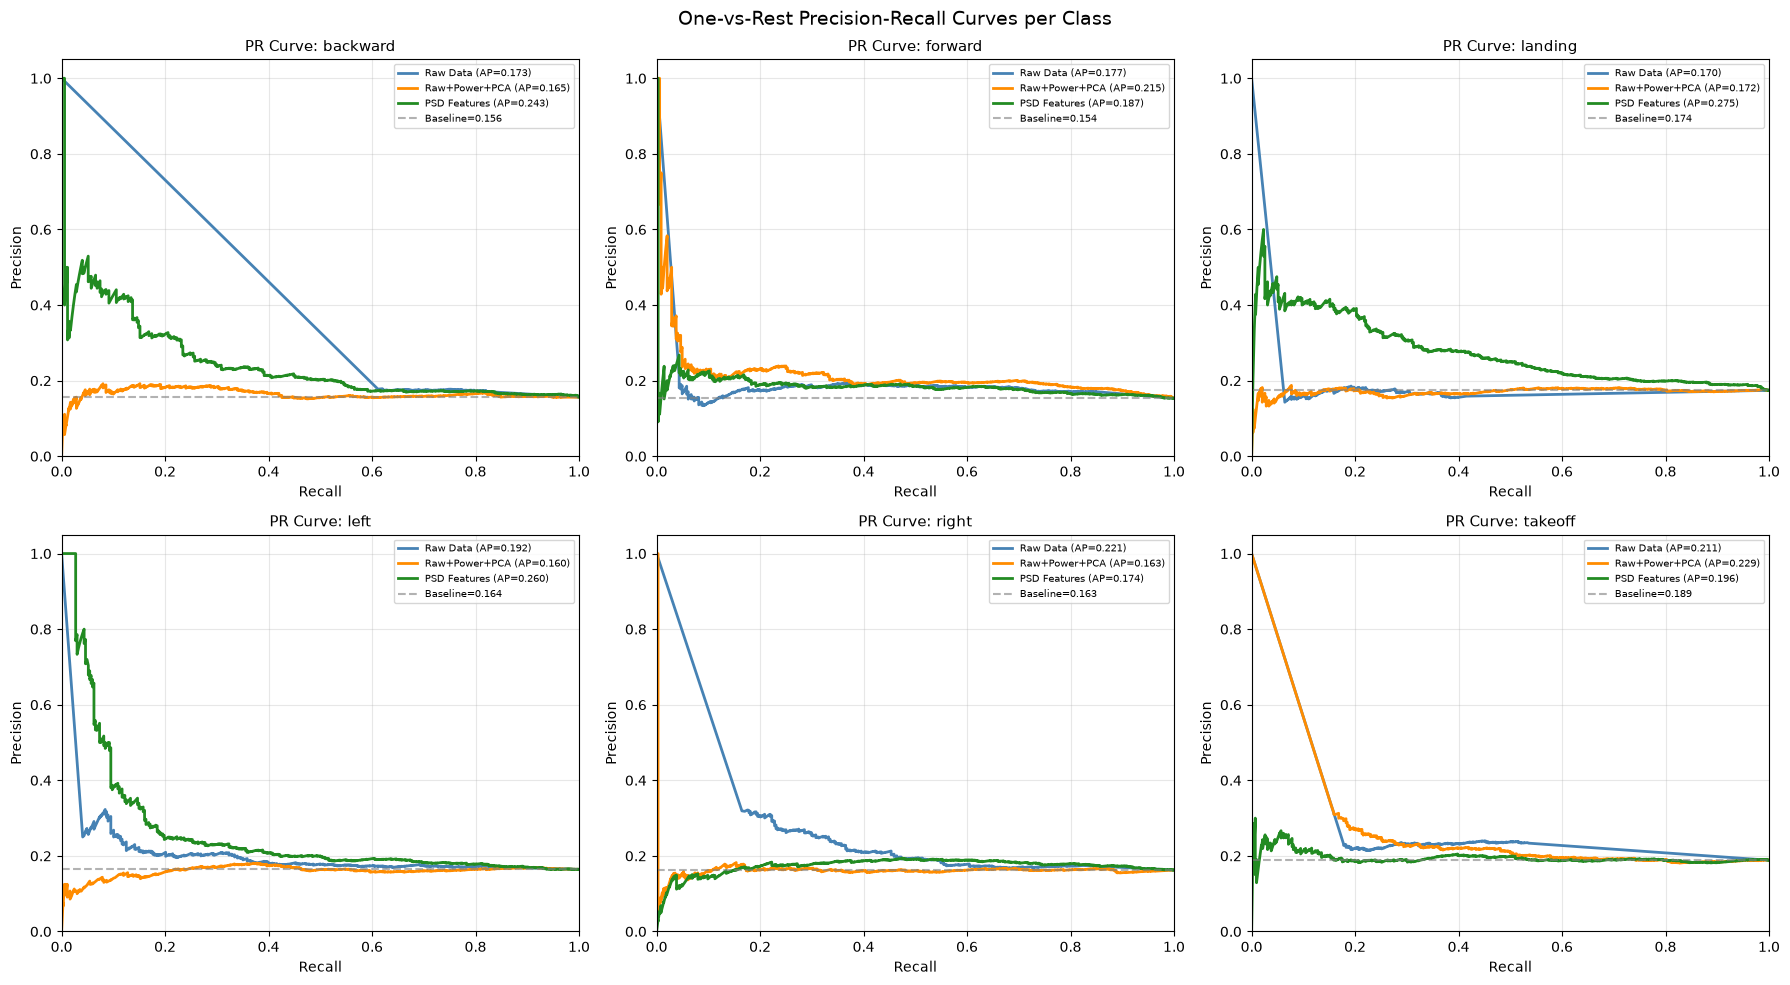

Saved one-vs-rest PR curves.


In [22]:
# ── 3. One-vs-Rest Precision-Recall Curves per Class ────────────────────────────
from sklearn.metrics import precision_recall_curve, average_precision_score
from sklearn.preprocessing import label_binarize

n_cls = len(le.classes_)
y_bin_exp = label_binarize(y_test_exp, classes=list(range(n_cls)))

exp_proba = {
    "Raw Data":    raw_clf.predict_proba(X_raw_test),
    "Raw+Power+PCA": raw_pca_clf.predict_proba(X_raw_test_pp),
    "PSD Features":psd_clf.predict_proba(X_psd_test),
}
colors_pr = ["steelblue", "darkorange", "forestgreen"]

fig, axes_pr = plt.subplots(2, 3, figsize=(18, 10))
for cls_idx, cls_name in enumerate(le.classes_):
    ax = axes_pr[cls_idx // 3, cls_idx % 3]
    for (exp_label, proba_mat), color in zip(exp_proba.items(), colors_pr):
        prob_pos = proba_mat[:, cls_idx]
        prec, rec, _ = precision_recall_curve(y_bin_exp[:, cls_idx], prob_pos)
        ap = average_precision_score(y_bin_exp[:, cls_idx], prob_pos)
        ax.plot(rec, prec, color=color, linewidth=2, label=f"{exp_label} (AP={ap:.3f})")
    # no-skill baseline
    pos_rate = y_bin_exp[:, cls_idx].mean()
    ax.axhline(pos_rate, color="gray", linestyle="--", alpha=0.6,
               label=f"Baseline={pos_rate:.3f}")
    ax.set_title(f"PR Curve: {cls_name}", fontsize=11)
    ax.set_xlabel("Recall")
    ax.set_ylabel("Precision")
    ax.set_xlim([0, 1])
    ax.set_ylim([0, 1.05])
    ax.legend(fontsize=7)
    ax.grid(alpha=0.3)

plt.suptitle("One-vs-Rest Precision-Recall Curves per Class", fontsize=14)
plt.tight_layout()
plt.savefig(
    pathlib.Path(model_path).with_name("gaussiannb_pr_curves.png"),
    dpi=120, bbox_inches="tight",
)
plt.show()
print("Saved one-vs-rest PR curves.")


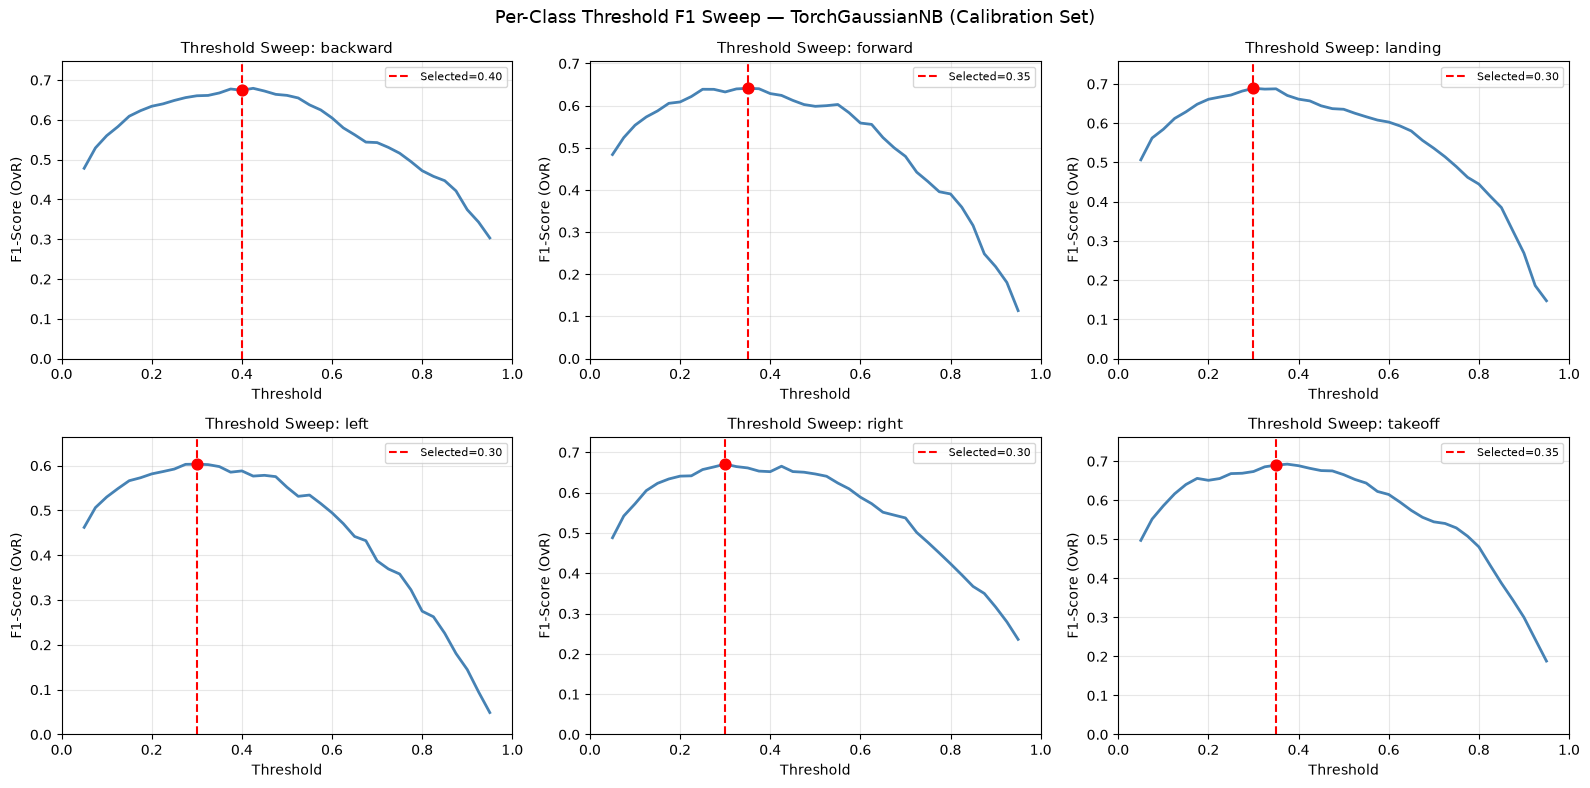

Saved threshold sweep plots.


In [23]:
# ── 4. Per-Class Threshold Sweep – TorchGaussianNB (Calibration Set) ────────────
sweep_grid = np.linspace(0.05, 0.95, 37)

fig, axes_sw = plt.subplots(2, 3, figsize=(16, 8))
for cls_idx, cls_name in enumerate(le.classes_):
    ax = axes_sw[cls_idx // 3, cls_idx % 3]
    y_true_bin = (y_calib == cls_idx).astype(np.int32)
    f1_curve = [
        f1_score(y_true_bin, (calib_probs[:, cls_idx] >= thr).astype(np.int32),
                 zero_division=0)
        for thr in sweep_grid
    ]
    ax.plot(sweep_grid, f1_curve, color="steelblue", linewidth=2)

    best_thr     = float(class_thresholds[cls_idx])
    best_thr_idx = int(np.argmin(np.abs(sweep_grid - best_thr)))
    best_f1_val  = f1_curve[best_thr_idx]

    ax.axvline(best_thr, color="red", linestyle="--", linewidth=1.5,
               label=f"Selected={best_thr:.2f}")
    ax.scatter([best_thr], [best_f1_val], color="red", s=60, zorder=5)
    ax.set_title(f"Threshold Sweep: {cls_name}", fontsize=11)
    ax.set_xlabel("Threshold")
    ax.set_ylabel("F1-Score (OvR)")
    ax.set_xlim([0, 1])
    ax.set_ylim([0, max(max(f1_curve) * 1.1, 0.1)])
    ax.legend(fontsize=8)
    ax.grid(alpha=0.3)

plt.suptitle("Per-Class Threshold F1 Sweep — TorchGaussianNB (Calibration Set)", fontsize=13)
plt.tight_layout()
plt.savefig(
    pathlib.Path(model_path).with_name("gaussiannb_threshold_sweep.png"),
    dpi=120, bbox_inches="tight",
)
plt.show()
print("Saved threshold sweep plots.")


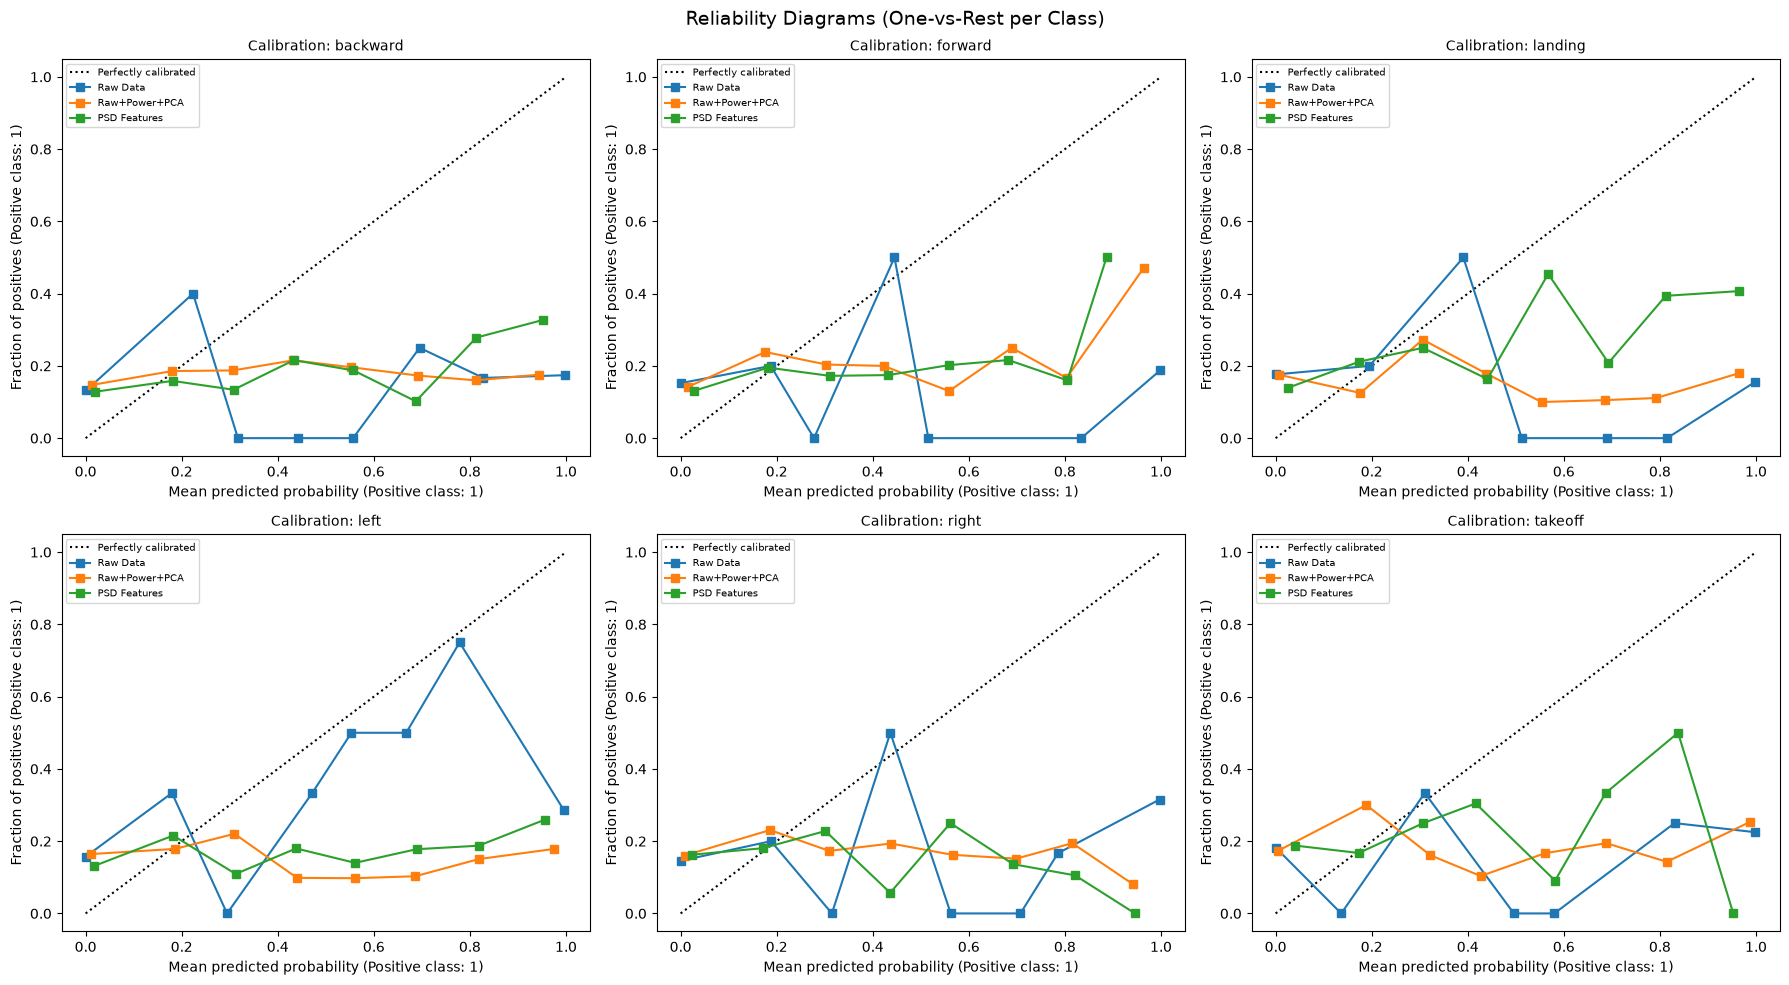

Saved calibration / reliability diagrams.


In [24]:
# ── 5. Reliability / Calibration Diagrams per Class ─────────────────────────────
from sklearn.calibration import CalibrationDisplay

exp_proba_cal = {
    "Raw Data":    raw_clf.predict_proba(X_raw_test),
    "Raw+Power+PCA": raw_pca_clf.predict_proba(X_raw_test_pp),
    "PSD Features":psd_clf.predict_proba(X_psd_test),
}
n_bins_cal = 8

fig, axes_cal = plt.subplots(2, 3, figsize=(18, 10))
for cls_idx, cls_name in enumerate(le.classes_):
    ax = axes_cal[cls_idx // 3, cls_idx % 3]
    y_true_bin = (y_test_exp == cls_idx).astype(int)
    for exp_label, proba_mat in exp_proba_cal.items():
        CalibrationDisplay.from_predictions(
            y_true_bin, proba_mat[:, cls_idx],
            n_bins=n_bins_cal, name=exp_label, ax=ax, strategy="uniform",
        )
    ax.set_title(f"Calibration: {cls_name}", fontsize=10)
    ax.legend(fontsize=7)

plt.suptitle("Reliability Diagrams (One-vs-Rest per Class)", fontsize=14)
plt.tight_layout()
plt.savefig(
    pathlib.Path(model_path).with_name("gaussiannb_calibration.png"),
    dpi=120, bbox_inches="tight",
)
plt.show()
print("Saved calibration / reliability diagrams.")


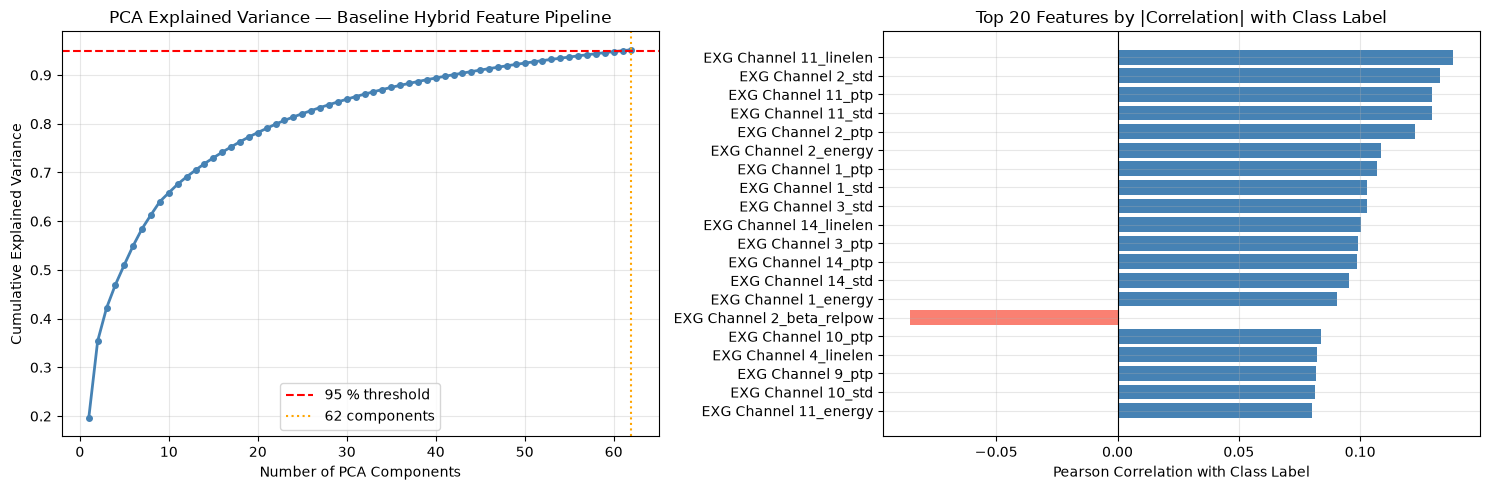

PCA uses 62 components to retain ≥95% variance.
Saved PCA explained-variance + feature correlation plot.


In [25]:
# ── 6. PCA Explained Variance Scree + Top Feature–Label Correlations ────────────
pca_step   = prep_baseline.named_steps["pca"]   # baseline (hybrid-feature) pipeline
expl_var   = np.cumsum(pca_step.explained_variance_ratio_)
n_comp_95  = int(np.searchsorted(expl_var, 0.95)) + 1

fig, (ax_pca, ax_corr) = plt.subplots(1, 2, figsize=(15, 5))

# ── Scree / cumulative explained variance
ax_pca.plot(np.arange(1, len(expl_var) + 1), expl_var,
            marker="o", markersize=4, linewidth=2, color="steelblue")
ax_pca.axhline(0.95, color="red",    linestyle="--", label="95 % threshold")
ax_pca.axvline(n_comp_95, color="orange", linestyle=":",
               label=f"{n_comp_95} components")
ax_pca.set_xlabel("Number of PCA Components")
ax_pca.set_ylabel("Cumulative Explained Variance")
ax_pca.set_title("PCA Explained Variance — Baseline Hybrid Feature Pipeline")
ax_pca.legend()
ax_pca.grid(alpha=0.3)

# ── Top 20 feature-label Pearson correlations (subsample for speed)
n_samp_corr = min(10_000, X_psd_df.shape[0])
row_sel = np.random.default_rng(42).choice(X_psd_df.shape[0], size=n_samp_corr, replace=False)
X_sub   = X_psd_df.iloc[row_sel].values  # (n_samp, 160)
y_sub   = y[row_sel]

feat_corrs = np.array([
    np.corrcoef(X_sub[:, i], y_sub)[0, 1]
    for i in range(X_sub.shape[1])
])
feat_corrs = np.nan_to_num(feat_corrs, nan=0.0)
feat_names = X_psd_df.columns.tolist()

top20_idx  = np.argsort(np.abs(feat_corrs))[::-1][:20]
top20_names = [feat_names[i] for i in top20_idx]
top20_vals  = [feat_corrs[i]  for i in top20_idx]

bar_colors = ["steelblue" if v >= 0 else "salmon" for v in top20_vals]
ax_corr.barh(top20_names[::-1], top20_vals[::-1], color=bar_colors[::-1])
ax_corr.axvline(0, color="black", linewidth=0.8)
ax_corr.set_xlabel("Pearson Correlation with Class Label")
ax_corr.set_title("Top 20 Features by |Correlation| with Class Label")
ax_corr.grid(alpha=0.3)

plt.tight_layout()
plt.savefig(
    pathlib.Path(model_path).with_name("gaussiannb_pca_feature_corr.png"),
    dpi=120, bbox_inches="tight",
)
plt.show()
print(f"PCA uses {n_comp_95} components to retain ≥95% variance.")
print("Saved PCA explained-variance + feature correlation plot.")


In [26]:
# ── 7. Runtime Comparison Table ─────────────────────────────────────────────────
import time as _time

rng_rt = np.random.default_rng(42)
n_rt   = min(5_000, len(y_all_exp))
sel_rt = np.sort(rng_rt.choice(len(y_all_exp), size=n_rt, replace=False))

Xr_rt = X_raw_all[sel_rt].copy()
Xp_rt = X_psd_all[sel_rt].copy()
yr_rt = y_all_exp[sel_rt].copy()

# Preprocess raw once for the Raw+PCA/Power config
prep_rt = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("power",   ParallelPowerTransformer(method="yeo-johnson", standardize=True)),
    ("pca",     PCA(n_components=0.95, svd_solver="covariance_eigh", random_state=42)),
])
Xr_rt_pp = prep_rt.fit_transform(Xr_rt).astype(np.float32)

rt_rows = []
for cfg_name, Xtr, Xte in [
    ("Raw flattened windows",          Xr_rt,    Xr_rt),
    ("Raw + PCA/Power (≤95 % var)",    Xr_rt_pp, Xr_rt_pp),
    ("PSD band powers (80 feats)",     Xp_rt,    Xp_rt),
]:
    clf_rt = SkGaussianNB()
    t0 = _time.perf_counter(); clf_rt.fit(Xtr, yr_rt);     t_train = _time.perf_counter() - t0
    t0 = _time.perf_counter(); _ = clf_rt.predict(Xte);    t_infer = _time.perf_counter() - t0
    rt_rows.append({
        "Configuration":         cfg_name,
        "n_features":            Xtr.shape[1],
        "Train Time (ms)":       round(t_train * 1_000, 2),
        "Inference Time (ms)":   round(t_infer * 1_000, 3),
        "Samples":               n_rt,
    })

# Feature cache load time
t0 = _time.perf_counter()
_ = np.load(cache_npz, allow_pickle=True)
t_cache = _time.perf_counter() - t0
rt_rows.append({
    "Configuration":       "Feature cache (.npz) load",
    "n_features":          "—",
    "Train Time (ms)":     "—",
    "Inference Time (ms)": "—",
    "Samples":             f"cache read: {t_cache * 1_000:.1f} ms",
})

rt_df = pd.DataFrame(rt_rows)
display(rt_df.style.set_caption(f"Runtime Comparison (GaussianNB, n={n_rt} samples)"))
rt_df.to_csv(
    pathlib.Path(model_path).with_name("gaussiannb_runtime_comparison.csv"), index=False
)
print("Saved runtime comparison table.")


,Configuration,n_features,Train Time (ms),Inference Time (ms),Samples
0,Raw flattened windows,1920,32.010000,106.894000,5000
1,Raw + PCA/Power (≤95 % var),387,6.240000,14.183000,5000
2,PSD band powers (80 feats),75,2.350000,3.123000,5000
3,Feature cache (.npz) load,—,—,—,cache read: 0.2 ms


Saved runtime comparison table.


In [27]:
# ── 8. Ablation Study: Feature-Set Comparison ───────────────────────────────────
# Uses the same group-stratified split as the main pipeline (train_idx / test_idx).
# Raw-window baseline row is taken directly from the defense comparison table.

stat_ends    = tuple(f"_{s}" for s in STAT_NAMES)
psd_end      = "_relpow"

avail_cols     = X_train_df.columns.tolist()
stat_cols_abl  = [c for c in avail_cols if c.endswith(stat_ends)]
psd_cols_abl   = [c for c in avail_cols if c.endswith(psd_end)]

Xtr_stats     = X_train_df[stat_cols_abl].values.astype(np.float32)
Xte_stats     = X_test_df[stat_cols_abl].values.astype(np.float32)
Xtr_psd_only  = X_train_df[psd_cols_abl].values.astype(np.float32)
Xte_psd_only  = X_test_df[psd_cols_abl].values.astype(np.float32)
Xtr_hybrid    = X_train_df.values.astype(np.float32)
Xte_hybrid    = X_test_df.values.astype(np.float32)

def _ablation_run(feat_name, Xtr, Xte, ytr, yte, use_pipeline=False):
    n_in = Xtr.shape[1]
    if use_pipeline:
        pp = Pipeline([
            ("imputer", SimpleImputer(strategy="median")),
            ("power",   ParallelPowerTransformer(method="yeo-johnson", standardize=True)),
            ("pca",     PCA(n_components=0.95, svd_solver="auto", random_state=42)),
        ])
        Xtr = pp.fit_transform(Xtr).astype(np.float32)
        Xte = pp.transform(Xte).astype(np.float32)
    else:
        imp = SimpleImputer(strategy="median")
        Xtr = imp.fit_transform(Xtr).astype(np.float32)
        Xte = imp.transform(Xte).astype(np.float32)
    n_used = Xtr.shape[1]
    clf = SkGaussianNB()
    clf.fit(Xtr, ytr)
    ypred = clf.predict(Xte)
    return {
        "Feature Set":   feat_name,
        "Feats In":      n_in,
        "Feats Used":    n_used,
        "Accuracy":      round(accuracy_score(yte, ypred), 4),
        "Macro-F1":      round(f1_score(yte, ypred, average="macro", zero_division=0), 4),
        "Balanced Acc":  round(balanced_accuracy_score(yte, ypred), 4),
    }

abl_rows = [
    _ablation_run("Time-Domain Stats only (80)",     Xtr_stats,    Xte_stats,    y_train, y_test),
    _ablation_run("PSD Band Powers only (80)",        Xtr_psd_only, Xte_psd_only, y_train, y_test),
    _ablation_run("Stats + PSD Hybrid (160)",         Xtr_hybrid,   Xte_hybrid,   y_train, y_test),
    _ablation_run("Stats + PSD + PCA/Power (95 %)",   Xtr_hybrid,   Xte_hybrid,   y_train, y_test,
                  use_pipeline=True),
]

# Improved chain on the same split (sklearn GaussianNB like the rows above): projection with and without labels
for abl_label, abl_proj in [("Improved 570 feats + participant z + PCA (95 %)", "pca"),
                            ("Improved 570 feats + participant z + LDA(5) [main pipeline]", "lda")]:
    proj_abl = (PCA(n_components=0.95, random_state=42) if abl_proj == "pca"
                else LinearDiscriminantAnalysis(n_components=5, solver="eigen", shrinkage="auto"))
    proj_abl.fit(Z_train, y_train)
    Ztr_abl, Zte_abl = proj_abl.transform(Z_train), proj_abl.transform(Z_test)
    ypred_abl = SkGaussianNB().fit(Ztr_abl, y_train).predict(Zte_abl)
    abl_rows.append({
        "Feature Set":  abl_label,
        "Feats In":     Z_train.shape[1],
        "Feats Used":   Ztr_abl.shape[1],
        "Accuracy":     round(accuracy_score(y_test, ypred_abl), 4),
        "Macro-F1":     round(f1_score(y_test, ypred_abl, average="macro", zero_division=0), 4),
        "Balanced Acc": round(balanced_accuracy_score(y_test, ypred_abl), 4),
    })

# Append raw-window baseline from the defense comparison (15 k subsample, different split)
raw_row = comparison_df[comparison_df["Experiment"].str.contains("Raw Data")].iloc[0]
abl_rows.append({
    "Feature Set":  "Raw Flattened Windows* (15 k subsample)",
    "Feats In":     int(EXP_WINDOW_SIZE * sig_base.shape[1]),
    "Feats Used":   int(EXP_WINDOW_SIZE * sig_base.shape[1]),
    "Accuracy":     round(float(raw_row["Accuracy"]), 4),
    "Macro-F1":     round(float(raw_row["Macro-F1"]), 4),
    "Balanced Acc": round(float(raw_row["Balanced Acc"]), 4),
})

ablation_df = (
    pd.DataFrame(abl_rows)
    .sort_values("Macro-F1", ascending=False)
    .reset_index(drop=True)
)

display(
    ablation_df.style
    .format({"Accuracy": "{:.4f}", "Macro-F1": "{:.4f}", "Balanced Acc": "{:.4f}"})
    .bar(subset=["Macro-F1"], color="#5fba7d", vmin=0, vmax=0.6)
    .set_caption("Ablation Study — Feature Set Comparison  (* different split, see note)")
)

ablation_df.to_csv(
    pathlib.Path(model_path).with_name("gaussiannb_ablation_table.csv"), index=False
)
print("Saved ablation table to gaussiannb_ablation_table.csv")
print(f"Note: all rows except * use the full {len(y)}-window group-stratified split (the notebook's split); the * Raw Windows row uses the defense subset.")


,Feature Set,Feats In,Feats Used,Accuracy,Macro-F1,Balanced Acc
0,Improved 570 feats + participant z + LDA(5) [main pipeline],570,5,0.4965,0.4947,0.4948
1,Improved 570 feats + participant z + PCA (95 %),570,299,0.4258,0.4269,0.4263
2,Stats + PSD + PCA/Power (95 %),150,62,0.2604,0.2598,0.2616
3,Stats + PSD Hybrid (160),150,150,0.2480,0.2336,0.2521
4,Time-Domain Stats only (80),75,75,0.2385,0.2210,0.2400
5,PSD Band Powers only (80),75,75,0.2042,0.1864,0.2084
6,Raw Flattened Windows* (15 k subsample),1920,1920,0.1997,0.1695,0.2031


Saved ablation table to gaussiannb_ablation_table.csv
Note: all rows except * use the full 12089-window group-stratified split (the notebook's split); the * Raw Windows row uses the defense subset.


## Best-Effort GaussianNB Ceiling (Nested CV + File-Holdout + Confidence Intervals)

This section estimates a statistically stronger GaussianNB ceiling using:

1. **Nested group-aware CV** (outer and inner splits by file group) for model selection without leakage.
2. **Repeated file-holdout evaluation** with multiple random seeds.
3. **95% confidence intervals** for Accuracy, Macro-F1, and Balanced Accuracy.

`groups` (source filenames) are used as holdout groups throughout.


In [28]:
# Nested group-aware CV to estimate GaussianNB ceiling (no file leakage)
import numpy as np
import pandas as pd
import pathlib
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import GroupKFold
from sklearn.naive_bayes import GaussianNB as SkGaussianNB
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from fast_preprocessing import ParallelPowerTransformer
from sklearn.decomposition import PCA
from sklearn.metrics import accuracy_score, f1_score, balanced_accuracy_score

required_vars = ["X_psd_df", "y", "groups", "model_path"]
missing_vars = [v for v in required_vars if v not in globals()]
if missing_vars:
    raise ValueError(
        f"Missing required variables: {missing_vars}. Run earlier training/data cells first (at least through defense setup)."
    )

RNG_CEIL = np.random.default_rng(42)

# Runtime guard for large notebooks; set to None to use all windows.
CEILING_MAX_WINDOWS = 30000

X_ceiling = X_psd_df.values.astype(np.float32)
y_ceiling = y.astype(np.int64)
g_ceiling = groups.astype(str)

ceil_rows = np.arange(len(y_ceiling))   # row indices into X_psd_df / X_imp (kept for the improved chain in the benchmark)
if CEILING_MAX_WINDOWS is not None and len(y_ceiling) > CEILING_MAX_WINDOWS:
    idx_ce = np.sort(RNG_CEIL.choice(len(y_ceiling), size=CEILING_MAX_WINDOWS, replace=False))
    X_ceiling = X_ceiling[idx_ce]
    y_ceiling = y_ceiling[idx_ce]
    g_ceiling = g_ceiling[idx_ce]
    ceil_rows = idx_ce

print(f"Ceiling dataset windows: {len(y_ceiling)}")
print(f"Unique file groups: {len(np.unique(g_ceiling))}")

# Search space kept small and robust for GaussianNB
var_grid = [1e-12, 1e-10, 1e-9, 1e-8, 1e-7, 1e-6]
use_pca_grid = [False, True]

def make_preprocessor(use_pca: bool):
    steps = [("imputer", SimpleImputer(strategy="median"))]
    if use_pca:
        steps.extend([
            ("power", ParallelPowerTransformer(method="yeo-johnson", standardize=True)),
            ("pca", PCA(n_components=0.95, svd_solver="auto", random_state=42)),
        ])
    return Pipeline(steps)

def make_gnb_pipeline(use_pca: bool, var_smoothing: float):
    steps = make_preprocessor(use_pca).steps
    steps.append(("gnb", SkGaussianNB(var_smoothing=var_smoothing)))
    return Pipeline(steps)

n_groups_outer = len(np.unique(g_ceiling))
outer_splits = max(3, min(5, n_groups_outer))
outer_cv = GroupKFold(n_splits=outer_splits)

nested_rows = []

for outer_fold, (tr_idx, te_idx) in enumerate(outer_cv.split(X_ceiling, y_ceiling, groups=g_ceiling), start=1):
    X_tr, X_te = X_ceiling[tr_idx], X_ceiling[te_idx]
    y_tr, y_te = y_ceiling[tr_idx], y_ceiling[te_idx]
    g_tr = g_ceiling[tr_idx]

    n_groups_inner = len(np.unique(g_tr))
    inner_splits = max(3, min(4, n_groups_inner))
    inner_cv = GroupKFold(n_splits=inner_splits)

    # var_smoothing only affects the GaussianNB step, so the expensive preprocessing
    # (PowerTransformer + PCA) is fitted once per inner split and reused across var_grid.
    inner_scores = {(use_pca, vs): [] for use_pca in use_pca_grid for vs in var_grid}
    for in_tr, in_va in inner_cv.split(X_tr, y_tr, groups=g_tr):
        for use_pca in use_pca_grid:
            prep_cv = make_preprocessor(use_pca)
            X_in_tr = prep_cv.fit_transform(X_tr[in_tr])
            X_in_va = prep_cv.transform(X_tr[in_va])
            for vs in var_grid:
                gnb_cv = SkGaussianNB(var_smoothing=vs).fit(X_in_tr, y_tr[in_tr])
                y_va_pred = gnb_cv.predict(X_in_va)
                inner_scores[(use_pca, vs)].append(f1_score(y_tr[in_va], y_va_pred, average="macro", zero_division=0))

    best_cfg = None
    best_score = -1.0

    for use_pca in use_pca_grid:
        for vs in var_grid:
            scores = inner_scores[(use_pca, vs)]
            score = float(np.mean(scores)) if scores else -1.0
            if score > best_score:
                best_score = score
                best_cfg = {"use_pca": use_pca, "var_smoothing": vs, "inner_macro_f1": score}

    best_model = make_gnb_pipeline(
        use_pca=best_cfg["use_pca"],
        var_smoothing=best_cfg["var_smoothing"],
    )
    best_model.fit(X_tr, y_tr)
    y_pred_outer = best_model.predict(X_te)

    nested_rows.append({
        "Fold": outer_fold,
        "Best Use PCA": best_cfg["use_pca"],
        "Best Var Smoothing": best_cfg["var_smoothing"],
        "InnerCV Macro-F1": best_cfg["inner_macro_f1"],
        "Outer Accuracy": accuracy_score(y_te, y_pred_outer),
        "Outer Macro-F1": f1_score(y_te, y_pred_outer, average="macro", zero_division=0),
        "Outer Balanced Acc": balanced_accuracy_score(y_te, y_pred_outer),
        "Outer n_test": len(y_te),
        "Outer n_files": len(np.unique(g_ceiling[te_idx])),
    })

nested_df = pd.DataFrame(nested_rows)
display(nested_df)

def mean_ci95(x):
    x = np.asarray(x, dtype=float)
    n = x.size
    if n <= 1:
        return float(np.mean(x)), float(np.mean(x)), float(np.mean(x))
    m = float(np.mean(x))
    s = float(np.std(x, ddof=1))
    half = 1.96 * s / np.sqrt(n)
    return m, m - half, m + half

summary_nested = []
for metric in ["Outer Accuracy", "Outer Macro-F1", "Outer Balanced Acc"]:
    m, lo, hi = mean_ci95(nested_df[metric].values)
    summary_nested.append({
        "Metric": metric,
        "Mean": m,
        "CI95 Low": lo,
        "CI95 High": hi,
        "n_folds": len(nested_df),
    })

nested_summary_df = pd.DataFrame(summary_nested)
print("\nNested CV summary (mean ± 95% CI):")
display(nested_summary_df.style.format({"Mean": "{:.4f}", "CI95 Low": "{:.4f}", "CI95 High": "{:.4f}"}))

nested_df.to_csv(pathlib.Path(model_path).with_name("gaussiannb_nested_cv_folds.csv"), index=False)
nested_summary_df.to_csv(pathlib.Path(model_path).with_name("gaussiannb_nested_cv_summary.csv"), index=False)
print("Saved nested CV fold-level and summary tables.")

Ceiling dataset windows: 12089
Unique file groups: 883


,Fold,Best Use PCA,Best Var Smoothing,InnerCV Macro-F1,Outer Accuracy,Outer Macro-F1,Outer Balanced Acc,Outer n_test,Outer n_files
0,1,True,1.000000e-12,0.291284,0.281521,0.279536,0.282426,2419,177
1,2,True,1.000000e-12,0.268974,0.283588,0.280378,0.282008,2419,177
2,3,True,1.000000e-12,0.274626,0.280215,0.274026,0.285134,2416,176
3,4,True,1.000000e-06,0.271539,0.292925,0.289055,0.300623,2417,176
4,5,True,1.000000e-12,0.274796,0.287014,0.285674,0.290752,2418,177



Nested CV summary (mean ± 95% CI):


,Metric,Mean,CI95 Low,CI95 High,n_folds
0,Outer Accuracy,0.2851,0.2806,0.2895,5
1,Outer Macro-F1,0.2817,0.2766,0.2868,5
2,Outer Balanced Acc,0.2882,0.2814,0.2950,5


Saved nested CV fold-level and summary tables.


Using repeated holdout config: use_pca=True, var_smoothing=1e-12

Repeated file-holdout summary:


,Metric,Mean,CI95 Low (percentile),CI95 High (percentile),Repeats
0,Accuracy,0.2619,0.2322,0.2925,20
1,Macro-F1,0.2579,0.2234,0.2888,20
2,Balanced Acc,0.2636,0.2301,0.2910,20


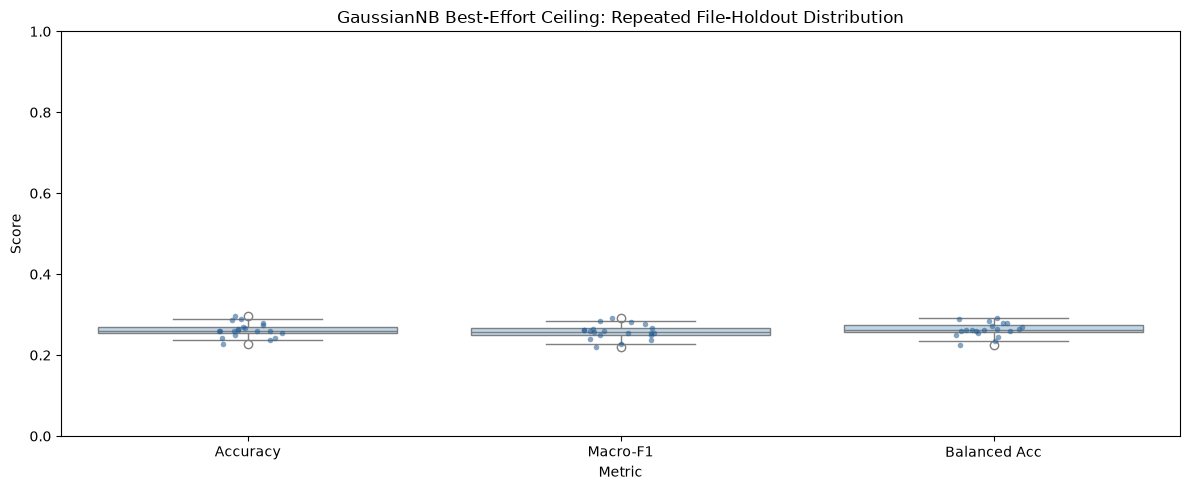

Saved repeated holdout run-level and CI summary tables.

Accuracy / performance improvement roadmap:


,Priority,Action,Why it helps
0,1,Move from GaussianNB to sequence-aware models ...,Captures temporal dependencies and non-Gaussia...
1,2,Use subject/session-aware splits and domain ad...,Reduces train-test drift and improves out-of-s...
2,3,Improve signal preprocessing (band-pass + notc...,Raises signal-to-noise ratio before classifica...
3,4,Increase robust feature diversity (CSP/Riemann...,Adds discriminative structure beyond independe...
4,5,Cost-sensitive training and focal losses for m...,Improves Macro-F1 and per-class recall under i...
5,6,"Use calibrated ensembles (e.g., LightGBM/XGBoo...",Usually stronger tabular baseline than Gaussia...


Saved model_improvement_roadmap.csv


In [29]:
# Repeated file-holdout evaluation + confidence intervals + practical improvement roadmap
import numpy as np
import pandas as pd
import pathlib
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import GroupShuffleSplit
from sklearn.metrics import accuracy_score, f1_score, balanced_accuracy_score

required_vars = ["nested_df", "X_ceiling", "y_ceiling", "g_ceiling", "model_path"]
missing_vars = [v for v in required_vars if v not in globals()]
if missing_vars:
    raise ValueError(
        f"Missing required variables: {missing_vars}. Run the preceding ceiling (nested CV) cell first."
    )

N_REPEATS = 20
TEST_SIZE = 0.2

best_use_pca = bool(nested_df["Best Use PCA"].mode().iloc[0])
best_vs = float(nested_df["Best Var Smoothing"].mode().iloc[0])

print(f"Using repeated holdout config: use_pca={best_use_pca}, var_smoothing={best_vs}")

holdout_rows = []
for seed in range(N_REPEATS):
    splitter = GroupShuffleSplit(n_splits=1, test_size=TEST_SIZE, random_state=seed)
    tr_idx, te_idx = next(splitter.split(X_ceiling, y_ceiling, groups=g_ceiling))

    model_rep = make_gnb_pipeline(use_pca=best_use_pca, var_smoothing=best_vs)
    model_rep.fit(X_ceiling[tr_idx], y_ceiling[tr_idx])
    y_pred = model_rep.predict(X_ceiling[te_idx])

    holdout_rows.append({
        "Seed": seed,
        "Accuracy": accuracy_score(y_ceiling[te_idx], y_pred),
        "Macro-F1": f1_score(y_ceiling[te_idx], y_pred, average="macro", zero_division=0),
        "Balanced Acc": balanced_accuracy_score(y_ceiling[te_idx], y_pred),
        "n_test": len(te_idx),
        "n_files_test": len(np.unique(g_ceiling[te_idx])),
    })

holdout_df = pd.DataFrame(holdout_rows)

def percentile_ci(x, lo=2.5, hi=97.5):
    x = np.asarray(x, dtype=float)
    return float(np.percentile(x, lo)), float(np.percentile(x, hi))

ci_rows = []
for metric in ["Accuracy", "Macro-F1", "Balanced Acc"]:
    vals = holdout_df[metric].values
    m = float(np.mean(vals))
    lo, hi = percentile_ci(vals)
    ci_rows.append({
        "Metric": metric,
        "Mean": m,
        "CI95 Low (percentile)": lo,
        "CI95 High (percentile)": hi,
        "Repeats": N_REPEATS,
    })

holdout_ci_df = pd.DataFrame(ci_rows)

print("\nRepeated file-holdout summary:")
display(holdout_ci_df.style.format({
    "Mean": "{:.4f}",
    "CI95 Low (percentile)": "{:.4f}",
    "CI95 High (percentile)": "{:.4f}",
}))

plot_h = holdout_df.melt(id_vars=["Seed"], value_vars=["Accuracy", "Macro-F1", "Balanced Acc"],
                         var_name="Metric", value_name="Score")
plt.figure(figsize=(12, 5))
sns.boxplot(data=plot_h, x="Metric", y="Score", color="#b7d7f0")
sns.stripplot(data=plot_h, x="Metric", y="Score", color="#1f5a91", alpha=0.55, size=4)
plt.ylim(0, 1)
plt.title("GaussianNB Best-Effort Ceiling: Repeated File-Holdout Distribution")
plt.tight_layout()
plt.savefig(pathlib.Path(model_path).with_name("gaussiannb_ceiling_holdout_distribution.png"), dpi=120, bbox_inches="tight")
plt.show()

holdout_df.to_csv(pathlib.Path(model_path).with_name("gaussiannb_repeated_holdout_runs.csv"), index=False)
holdout_ci_df.to_csv(pathlib.Path(model_path).with_name("gaussiannb_repeated_holdout_summary.csv"), index=False)
print("Saved repeated holdout run-level and CI summary tables.")

improvement_roadmap = pd.DataFrame([
    {"Priority": 1, "Action": "Move from GaussianNB to sequence-aware models (1D CNN / TCN / EEGNet / Transformer)",
     "Why it helps": "Captures temporal dependencies and non-Gaussian structure that NB ignores."},
    {"Priority": 2, "Action": "Use subject/session-aware splits and domain adaptation", 
     "Why it helps": "Reduces train-test drift and improves out-of-session generalization."},
    {"Priority": 3, "Action": "Improve signal preprocessing (band-pass + notch + artifact rejection/ICA)",
     "Why it helps": "Raises signal-to-noise ratio before classification."},
    {"Priority": 4, "Action": "Increase robust feature diversity (CSP/Riemannian covariance, wavelets, entropy)",
     "Why it helps": "Adds discriminative structure beyond independent per-feature Gaussian assumptions."},
    {"Priority": 5, "Action": "Cost-sensitive training and focal losses for minority commands",
     "Why it helps": "Improves Macro-F1 and per-class recall under imbalance."},
    {"Priority": 6, "Action": "Use calibrated ensembles (e.g., LightGBM/XGBoost + calibration)",
     "Why it helps": "Usually stronger tabular baseline than GaussianNB for heterogeneous EEG features."},
])

print("\nAccuracy / performance improvement roadmap:")
display(improvement_roadmap)
improvement_roadmap.to_csv(pathlib.Path(model_path).with_name("model_improvement_roadmap.csv"), index=False)
print("Saved model_improvement_roadmap.csv")

Benchmark windows: 12089 | unique files: 883


,Model,Accuracy Mean,Accuracy Std,Macro-F1 Mean,Macro-F1 Std,Balanced Acc Mean,Balanced Acc Std
0,GaussianNB (subject-specific chain),0.8411,0.0164,0.8388,0.0194,0.8413,0.0190
1,RandomForest,0.5124,0.0310,0.5064,0.0355,0.5093,0.0363
2,"GaussianNB (improved chain, LDA)",0.4897,0.0192,0.4858,0.0199,0.4870,0.0195
3,GaussianNB,0.2259,0.0253,0.2068,0.0232,0.2284,0.0234
4,JAX Deep Learning (MLP),0.1811,0.0080,0.1790,0.0087,0.1815,0.0077


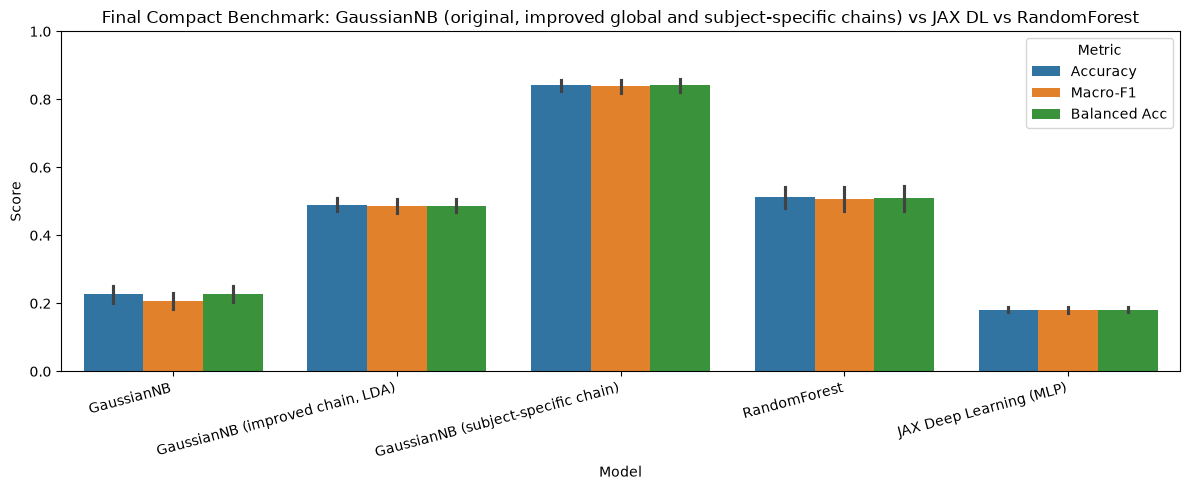

Saved final project-model benchmark artifacts:
 - final_model_benchmark_project_models_runs.csv
 - final_model_benchmark_project_models_summary.csv
 - final_model_benchmark_project_models.png


In [30]:
# Final compact benchmark: GaussianNB vs JAX deep learning vs Random Forest (repeated group-holdout)
import numpy as np
import pandas as pd
import pathlib
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import GroupShuffleSplit
from sklearn.impute import SimpleImputer
from fast_preprocessing import ParallelPowerTransformer
from sklearn.pipeline import Pipeline
from sklearn.metrics import accuracy_score, f1_score, balanced_accuracy_score
from sklearn.ensemble import RandomForestClassifier
from sklearn.naive_bayes import GaussianNB as SkGaussianNB

# ---------------------------
# Resolve benchmark dataset
# ---------------------------
required_any = ["X_ceiling", "y_ceiling", "g_ceiling"]
if all(v in globals() for v in required_any):
    X_bench = X_ceiling.copy()
    y_bench = y_ceiling.copy()
    g_bench = g_ceiling.copy()
elif all(v in globals() for v in ["X_psd_df", "y", "groups"]):
    X_bench = X_psd_df.values.astype(np.float32)
    y_bench = y.astype(np.int64)
    g_bench = groups.astype(str)
else:
    raise ValueError("Missing benchmark inputs. Run data/feature cells first.")

if "model_path" not in globals():
    model_path = "torch_gaussiannb_improved_features.pth"

# Runtime cap to keep JAX training practical inside notebook
BENCH_MAX_WINDOWS = 18000
rng_bench = np.random.default_rng(42)
bench_rows = ceil_rows if "ceil_rows" in globals() else np.arange(len(y_bench))   # rows of X_imp matching X_bench
if BENCH_MAX_WINDOWS is not None and len(y_bench) > BENCH_MAX_WINDOWS:
    sel = np.sort(rng_bench.choice(len(y_bench), size=BENCH_MAX_WINDOWS, replace=False))
    X_bench = X_bench[sel]
    y_bench = y_bench[sel]
    g_bench = g_bench[sel]
    bench_rows = bench_rows[sel]
X_imp_bench, parts_bench = X_imp[bench_rows], parts[bench_rows]
X_subj_bench = X_subj[bench_rows]

print(f"Benchmark windows: {len(y_bench)} | unique files: {len(np.unique(g_bench))}")

# ---------------------------
# Shared preprocessing
# ---------------------------
prep_common = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("power", ParallelPowerTransformer(method="yeo-johnson", standardize=True)),
])

# ---------------------------
# Models
# ---------------------------
def make_random_forest():
    return RandomForestClassifier(
        n_estimators=300,
        class_weight="balanced_subsample",
        random_state=42,
        n_jobs=-1,
    )

def make_gaussiannb():
    return SkGaussianNB(var_smoothing=1e-9)

# ---------------------------
# JAX MLP (project-style deep learning)
# ---------------------------
# The MLP is small, so run JAX on the CPU and stop it reserving GPU memory: by default JAX
# preallocates 75% of the GPU, which fails when another kernel is already using it.
import os
os.environ.setdefault("JAX_PLATFORMS", "cpu")
os.environ.setdefault("XLA_PYTHON_CLIENT_PREALLOCATE", "false")
if "jax" in sys.modules:
    print("Note: JAX was already imported in this kernel; restart the kernel for the CPU setting to apply.")

try:
    import jax
    import jax.numpy as jnp
    from jax import random, grad
    JAX_AVAILABLE = True
except Exception:
    JAX_AVAILABLE = False


def train_predict_jax_mlp(X_train, y_train, X_test, seed=42, hidden=128, epochs=25, batch_size=512, lr=1e-3):
    if not JAX_AVAILABLE:
        raise RuntimeError("JAX is not available in the current environment.")

    n_features = X_train.shape[1]
    n_classes = int(np.max(y_train)) + 1

    key = random.PRNGKey(seed)
    k1, k2 = random.split(key)

    params = {
        "W1": random.normal(k1, (n_features, hidden), dtype=jnp.float32) * jnp.sqrt(2.0 / n_features),
        "b1": jnp.zeros((hidden,), dtype=jnp.float32),
        "W2": random.normal(k2, (hidden, n_classes), dtype=jnp.float32) * jnp.sqrt(2.0 / hidden),
        "b2": jnp.zeros((n_classes,), dtype=jnp.float32),
    }

    def forward(p, X):
        h = jax.nn.relu(X @ p["W1"] + p["b1"])
        return h @ p["W2"] + p["b2"]

    def loss_fn(p, X, y):
        logits = forward(p, X)
        y_oh = jax.nn.one_hot(y, n_classes)
        logp = jax.nn.log_softmax(logits, axis=1)
        return -jnp.mean(jnp.sum(y_oh * logp, axis=1))

    @jax.jit
    def sgd_step(p, xb, yb):
        grads = grad(loss_fn)(p, xb, yb)
        return jax.tree_util.tree_map(lambda w, g: w - lr * g, p, grads)

    Xtr = jnp.asarray(X_train, dtype=jnp.float32)
    ytr = jnp.asarray(y_train, dtype=jnp.int32)
    n = X_train.shape[0]

    # Simple SGD loop for reproducible, lightweight benchmarking
    for ep in range(epochs):
        perm = np.random.default_rng(seed + ep).permutation(n)
        for i in range(0, n, batch_size):
            idx = perm[i:i + batch_size]
            xb = Xtr[idx]
            yb = ytr[idx]
            params = sgd_step(params, xb, yb)

    logits_te = forward(params, jnp.asarray(X_test, dtype=jnp.float32))
    y_pred = np.asarray(jnp.argmax(logits_te, axis=1), dtype=np.int64)
    return y_pred


# ---------------------------
# Repeated group-holdout benchmark
# ---------------------------
N_BENCH_REPEATS = 6
TEST_SIZE = 0.2

rows = []
for seed in range(N_BENCH_REPEATS):
    splitter = GroupShuffleSplit(n_splits=1, test_size=TEST_SIZE, random_state=seed)
    tr_idx, te_idx = next(splitter.split(X_bench, y_bench, groups=g_bench))

    Xtr_raw, Xte_raw = X_bench[tr_idx], X_bench[te_idx]
    ytr, yte = y_bench[tr_idx], y_bench[te_idx]

    Xtr = prep_common.fit_transform(Xtr_raw).astype(np.float32)
    Xte = prep_common.transform(Xte_raw).astype(np.float32)

    # GaussianNB
    gnb = make_gaussiannb()
    gnb.fit(Xtr, ytr)
    ypred_gnb = gnb.predict(Xte)
    rows.append({
        "Seed": seed,
        "Model": "GaussianNB",
        "Accuracy": accuracy_score(yte, ypred_gnb),
        "Macro-F1": f1_score(yte, ypred_gnb, average="macro", zero_division=0),
        "Balanced Acc": balanced_accuracy_score(yte, ypred_gnb),
        "n_test": len(yte),
        "n_files_test": len(np.unique(g_bench[te_idx])),
    })

    # GaussianNB, improved chain (570 features -> participant z-score -> projection -> GaussianNB), same split
    logp_imp = _improved_chain(X_imp_bench[tr_idx], ytr, parts_bench[tr_idx], X_imp_bench[te_idx], parts_bench[te_idx])
    ypred_imp = logp_imp.argmax(axis=1)
    rows.append({
        "Seed": seed,
        "Model": f"GaussianNB (improved chain, {PROJECTION.upper()})",
        "Accuracy": accuracy_score(yte, ypred_imp),
        "Macro-F1": f1_score(yte, ypred_imp, average="macro", zero_division=0),
        "Balanced Acc": balanced_accuracy_score(yte, ypred_imp),
        "n_test": len(yte),
        "n_files_test": len(np.unique(g_bench[te_idx])),
    })

    # GaussianNB, subject-specific chain (435 features, own LDA + own GaussianNB per participant, global fallback), same split
    logp_sub = _subject_chain(X_subj_bench[tr_idx], ytr, parts_bench[tr_idx], X_subj_bench[te_idx], parts_bench[te_idx])
    ypred_sub = logp_sub.argmax(axis=1)
    rows.append({
        "Seed": seed,
        "Model": "GaussianNB (subject-specific chain)",
        "Accuracy": accuracy_score(yte, ypred_sub),
        "Macro-F1": f1_score(yte, ypred_sub, average="macro", zero_division=0),
        "Balanced Acc": balanced_accuracy_score(yte, ypred_sub),
        "n_test": len(yte),
        "n_files_test": len(np.unique(g_bench[te_idx])),
    })

    # Random Forest
    rf = make_random_forest()
    rf.fit(Xtr, ytr)
    ypred_rf = rf.predict(Xte)
    rows.append({
        "Seed": seed,
        "Model": "RandomForest",
        "Accuracy": accuracy_score(yte, ypred_rf),
        "Macro-F1": f1_score(yte, ypred_rf, average="macro", zero_division=0),
        "Balanced Acc": balanced_accuracy_score(yte, ypred_rf),
        "n_test": len(yte),
        "n_files_test": len(np.unique(g_bench[te_idx])),
    })

    # JAX Deep Learning
    if JAX_AVAILABLE:
        ypred_jax = train_predict_jax_mlp(Xtr, ytr, Xte, seed=42 + seed)
        rows.append({
            "Seed": seed,
            "Model": "JAX Deep Learning (MLP)",
            "Accuracy": accuracy_score(yte, ypred_jax),
            "Macro-F1": f1_score(yte, ypred_jax, average="macro", zero_division=0),
            "Balanced Acc": balanced_accuracy_score(yte, ypred_jax),
            "n_test": len(yte),
            "n_files_test": len(np.unique(g_bench[te_idx])),
        })
    else:
        print("JAX not available; JAX deep learning row omitted.")

bench_runs_df = pd.DataFrame(rows)
if bench_runs_df.empty:
    raise ValueError("No benchmark rows produced.")

summary = (
    bench_runs_df
    .groupby("Model", as_index=False)
    .agg({
        "Accuracy": ["mean", "std"],
        "Macro-F1": ["mean", "std"],
        "Balanced Acc": ["mean", "std"],
    })
)
summary.columns = [
    "Model",
    "Accuracy Mean", "Accuracy Std",
    "Macro-F1 Mean", "Macro-F1 Std",
    "Balanced Acc Mean", "Balanced Acc Std",
]
summary = summary.sort_values("Macro-F1 Mean", ascending=False).reset_index(drop=True)

display(summary.style.format({
    "Accuracy Mean": "{:.4f}", "Accuracy Std": "{:.4f}",
    "Macro-F1 Mean": "{:.4f}", "Macro-F1 Std": "{:.4f}",
    "Balanced Acc Mean": "{:.4f}", "Balanced Acc Std": "{:.4f}",
}))

plot_df = bench_runs_df.melt(
    id_vars=["Seed", "Model"],
    value_vars=["Accuracy", "Macro-F1", "Balanced Acc"],
    var_name="Metric", value_name="Score"
)

plt.figure(figsize=(12, 5))
sns.barplot(data=plot_df, x="Model", y="Score", hue="Metric", errorbar="sd")
plt.ylim(0, 1)
plt.title("Final Compact Benchmark: GaussianNB (original, improved global and subject-specific chains) vs JAX DL vs RandomForest")
plt.xticks(rotation=15, ha="right")
plt.tight_layout()
plt.savefig(pathlib.Path(model_path).with_name("final_model_benchmark_project_models.png"), dpi=120, bbox_inches="tight")
plt.show()

bench_runs_df.to_csv(pathlib.Path(model_path).with_name("final_model_benchmark_project_models_runs.csv"), index=False)
summary.to_csv(pathlib.Path(model_path).with_name("final_model_benchmark_project_models_summary.csv"), index=False)

print("Saved final project-model benchmark artifacts:")
print(" - final_model_benchmark_project_models_runs.csv")
print(" - final_model_benchmark_project_models_summary.csv")
print(" - final_model_benchmark_project_models.png")

## Calibrated Trial-Level GaussianNB (per-person calibration, one decision per trial)

This section builds a model the way a deployed system would use it with a new person:

- **One decision per trial.** Each trial is described by the log mu (8–13 Hz) and beta (13–30 Hz) power of every channel, over its whole kept cue period, instead of many 1 s windows.
- **Per-person calibration.** Each participant's features are z-scored with statistics from their own calibration data only: their first session, or the first half of their recordings when there is one session. No labels are used, as with a short calibration recording before a new user starts.
- **Decorrelation.** Band powers of neighbouring channels are correlated in real EEG, which breaks GaussianNB's independence assumption. A PCA whitening step (fitted on the training participants) decorrelates the features before GaussianNB; shrinkage LDA is shown for comparison.
- **Honest test.** Leave-one-participant-out: the model never sees the test person's labels, and their calibration data only sets their normalisation.

On the synthetic sessions (`synthetic_sessions.py`), calibration raised held-out-participant accuracy from 54% to 93% with `--effect 0.2`. The no-signal control stayed at chance (15%), so the gain is not leakage. On `Data_clean` it stays at chance: the recordings carry no command signal to recover.


Trials/recordings with >= 2 s of kept EEG: 883 from 18 participants
Per class: {'backward': 134, 'forward': 141, 'landing': 156, 'left': 147, 'right': 143, 'takeoff': 162}
Features: log mu, beta power x 15 channels = 30


/home/prasndhdl/ai_env/lib/python3.12/site-packages/sklearn/metrics/_classification.py:2939: UserWarning: y_pred contains classes not in y_true
  warnings.warn("y_pred contains classes not in y_true")
/home/prasndhdl/ai_env/lib/python3.12/site-packages/sklearn/metrics/_classification.py:2939: UserWarning: y_pred contains classes not in y_true
  warnings.warn("y_pred contains classes not in y_true")
/home/prasndhdl/ai_env/lib/python3.12/site-packages/sklearn/metrics/_classification.py:2939: UserWarning: y_pred contains classes not in y_true
  warnings.warn("y_pred contains classes not in y_true")


Mean |correlation| between features within a command: 0.39 (0 = independent, as GaussianNB assumes)


/home/prasndhdl/ai_env/lib/python3.12/site-packages/sklearn/metrics/_classification.py:2939: UserWarning: y_pred contains classes not in y_true
  warnings.warn("y_pred contains classes not in y_true")


,Method,accuracy,balanced_accuracy,macro_f1,n_test_trials,most_predicted
0,"GaussianNB, no normalisation",0.225,0.141,0.134,444,left (135 of 444)
1,"GaussianNB, calibrated",0.216,0.127,0.131,444,takeoff (110 of 444)
2,"PCA whitening + GaussianNB, calibrated",0.212,0.260,0.139,444,right (125 of 444)
3,"Shrinkage LDA, calibrated (comparison)",0.178,0.173,0.121,444,landing (109 of 444)


method,"GaussianNB, no normalisation","GaussianNB, calibrated","PCA whitening + GaussianNB, calibrated","Shrinkage LDA, calibrated (comparison)"
participant,,,,
G01/person08,0.103,0.069,0.069,0.069
G01/person09,0.333,0.133,0.067,0.100
G01/person10,0.357,0.357,0.321,0.429
G03/person01,1.000,0.000,0.000,0.000
G03/person03,0.267,0.167,0.267,0.267
G03/person04,0.133,0.167,0.167,0.200
G03/person05,0.000,0.100,0.233,0.067
G03/person06,0.067,0.367,0.333,0.200
G03/person07,0.333,0.200,0.167,0.133


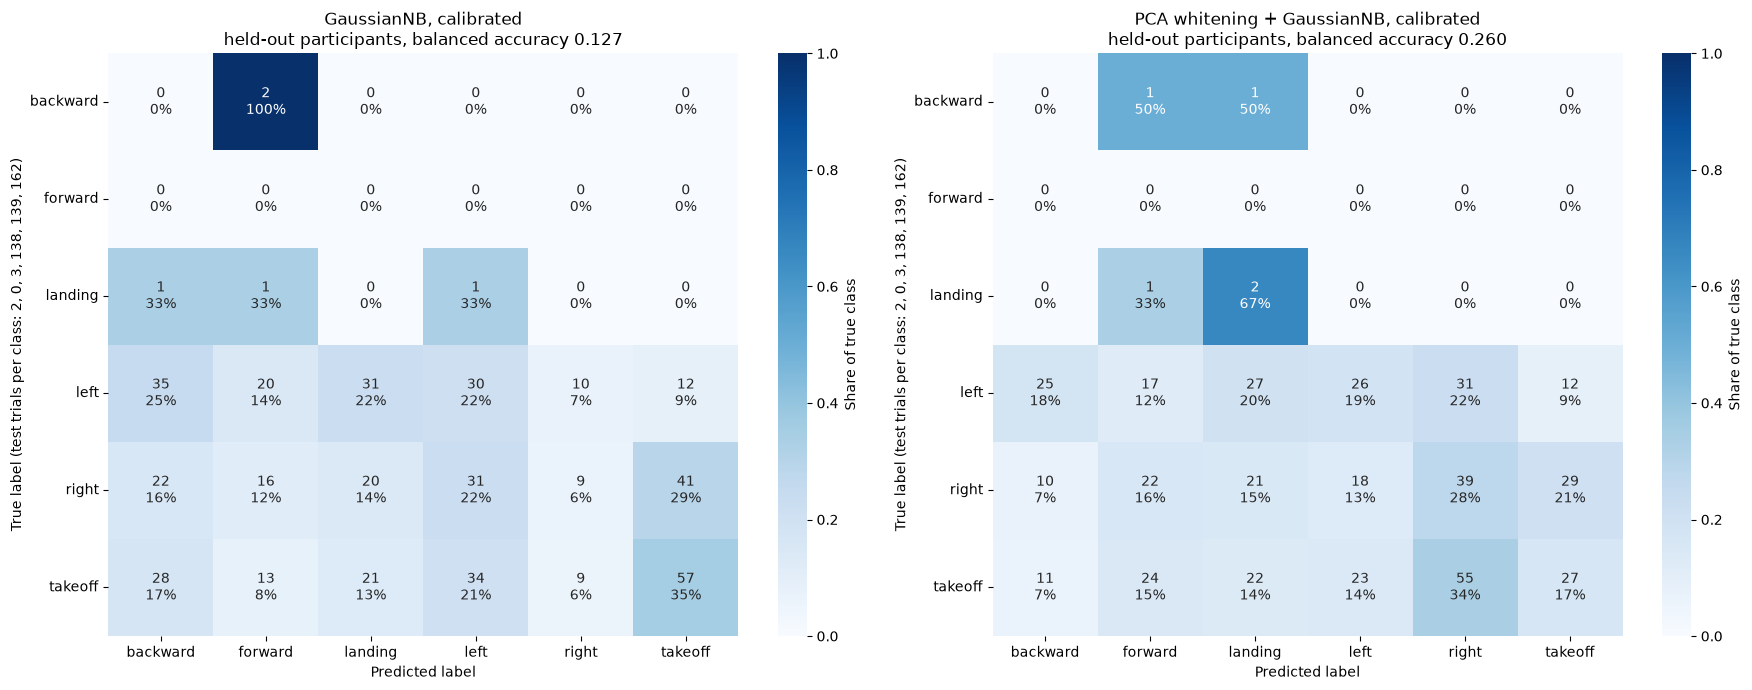

Saved gaussiannb_calibrated_trial_level.csv and gaussiannb_calibrated_trial_cm.png


In [31]:
# Calibrated trial-level GaussianNB: one decision per trial, per-person calibration normalisation
import pathlib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.signal import welch
from sklearn.naive_bayes import GaussianNB as SkGaussianNB
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn.metrics import accuracy_score, balanced_accuracy_score, f1_score, confusion_matrix

if "recordings" not in globals():
    raise ValueError("Run cell 1 first (it loads `recordings`).")

CAL_BANDS = {"mu": (8.0, 13.0), "beta": (13.0, 30.0)}
CAL_MIN_SECONDS = 2.0      # a trial needs at least this much kept EEG
CAL_CLASSES = sorted({r["label"] for r in recordings})


def trial_features(item):
    """Log mu/beta power per channel over all kept segments of one trial (or one recording)."""
    fs = item["sfreq"]
    segs = [s for s in item["segments"] if len(s) >= int(fs)]
    if sum(len(s) for s in segs) < CAL_MIN_SECONDS * fs:
        return None
    psds, weights = [], []
    for s in segs:
        f, p = welch(s.T, fs=fs, nperseg=min(len(s), int(2 * fs)), axis=-1)
        psds.append(p)
        weights.append(len(s))
    psd = np.average(np.stack(psds), axis=0, weights=weights)          # (channels, freqs)
    return np.concatenate([np.log(np.trapezoid(psd[:, (f >= lo) & (f < hi)], f[(f >= lo) & (f < hi)], axis=-1) + 1e-12)
                           for lo, hi in CAL_BANDS.values()])


rows = []
for item in recordings:
    x = trial_features(item)
    if x is not None:
        rows.append(dict(x=x, label=item["label"], participant=item["participant"],
                         session=item.get("session", ""), unit=item["path"]))
cal_df = pd.DataFrame(rows)

# Calibration data per participant, never labelled: their first session when there are several;
# otherwise the first half of their trials/recordings in recording order.
def calibration_mask(df):
    cal = np.zeros(len(df), dtype=bool)
    for p, g in df.groupby("participant"):
        sessions = sorted(s for s in g["session"].unique() if s)
        if len(sessions) > 1:
            cal[g.index[g["session"] == sessions[0]]] = True
        else:
            order = g.sort_values("unit").index
            cal[order[: len(order) // 2]] = True
    return cal

cal_df["calibration"] = calibration_mask(cal_df)
# A participant needs at least 2 calibration trials to estimate their normalisation statistics
n_cal = cal_df.groupby("participant")["calibration"].sum()
too_few = sorted(n_cal[n_cal < 2].index)
if too_few:
    print(f"Skipping participants with < 2 calibration trials: {too_few}")
    cal_df = cal_df[~cal_df["participant"].isin(too_few)].reset_index(drop=True)
X_trial = np.vstack(cal_df["x"].to_numpy())
y_trial = cal_df["label"].to_numpy()
p_trial = cal_df["participant"].to_numpy()
is_cal = cal_df["calibration"].to_numpy()

print(f"Trials/recordings with >= {CAL_MIN_SECONDS:.0f} s of kept EEG: {len(cal_df)} "
      f"from {cal_df['participant'].nunique()} participants")
print("Per class:", cal_df["label"].value_counts().sort_index().to_dict())
print(f"Features: log {', '.join(CAL_BANDS)} power x {X_trial.shape[1] // len(CAL_BANDS)} channels = {X_trial.shape[1]}")


def normalise(X, participants, calibration):
    """z-score each participant's features with statistics from their own calibration data only."""
    Z = np.empty_like(X)
    for p in np.unique(participants):
        m = participants == p
        ref = X[m & calibration]
        Z[m] = (X[m] - ref.mean(axis=0)) / (ref.std(axis=0) + 1e-9)
    return Z


# Classifiers compared on the same calibrated trial features. Real EEG band powers of neighbouring
# channels are correlated; GaussianNB assumes independent features, so it counts shared evidence
# several times and tends to pile ambiguous trials onto one command. PCA whitening decorrelates the
# features first (fitted on training participants only), which keeps GaussianNB as the classifier.
# Shrinkage LDA models the correlations directly and is shown for comparison.
CAL_METHODS = {
    "GaussianNB, no normalisation": (False, lambda: make_pipeline(StandardScaler(), SkGaussianNB())),
    "GaussianNB, calibrated": (True, lambda: make_pipeline(StandardScaler(), SkGaussianNB())),
    "PCA whitening + GaussianNB, calibrated": (True, lambda: make_pipeline(StandardScaler(), PCA(whiten=True), SkGaussianNB())),
    "Shrinkage LDA, calibrated (comparison)": (True, lambda: make_pipeline(
        StandardScaler(), LinearDiscriminantAnalysis(solver="lsqr", shrinkage="auto"))),
}
CAL_BEST = "PCA whitening + GaussianNB, calibrated"

# Leave-one-participant-out: train on everyone else (all their trials), test on the held-out
# person's non-calibration trials. Their calibration data only sets their normalisation.
X_cal_norm = normalise(X_trial, p_trial, is_cal)
cal_results, cal_preds = {}, {}
for method, (use_calibration, make_model) in CAL_METHODS.items():
    Z = X_cal_norm if use_calibration else X_trial
    y_true, y_pred, per_person = [], [], []
    for p in np.unique(p_trial):
        train, test = p_trial != p, (p_trial == p) & ~is_cal
        if not test.any() or len(np.unique(y_trial[train])) < len(CAL_CLASSES):
            continue
        clf = make_model().fit(Z[train], y_trial[train])
        pred = clf.predict(Z[test])
        y_true += list(y_trial[test]); y_pred += list(pred)
        per_person.append(dict(participant=p, method=method, n_test=int(test.sum()),
                               accuracy=accuracy_score(y_trial[test], pred)))
    counts = pd.Series(y_pred).value_counts()
    cal_results[method] = dict(accuracy=accuracy_score(y_true, y_pred),
                               balanced_accuracy=balanced_accuracy_score(y_true, y_pred),
                               macro_f1=f1_score(y_true, y_pred, average="macro"),
                               n_test_trials=len(y_true),
                               most_predicted=f"{counts.index[0]} ({counts.iloc[0]} of {len(y_pred)})",
                               per_person=per_person)
    cal_preds[method] = (np.array(y_true), np.array(y_pred))

within_corr = np.mean([np.abs(np.corrcoef(X_cal_norm[y_trial == c].T)[np.triu_indices(X_trial.shape[1], 1)]).mean()
                       for c in CAL_CLASSES])
print(f"Mean |correlation| between features within a command: {within_corr:.2f} "
      "(0 = independent, as GaussianNB assumes)")
summary_cal = pd.DataFrame([dict(Method=m, **{k: v for k, v in r.items() if k != "per_person"})
                            for m, r in cal_results.items()])
display(summary_cal.style.format({"accuracy": "{:.3f}", "balanced_accuracy": "{:.3f}", "macro_f1": "{:.3f}"})
        .set_caption(f"Held-out participants, one decision per trial (chance {1 / len(CAL_CLASSES):.3f})"))
per_person_df = pd.DataFrame([row for r in cal_results.values() for row in r["per_person"]])
display(per_person_df.pivot(index="participant", columns="method", values="accuracy")[list(CAL_METHODS)]
        .style.format("{:.3f}").set_caption("Accuracy per held-out participant"))

# Confusion matrices: calibrated GaussianNB without and with whitening (counts and % of each true class)
fig, axes_cal = plt.subplots(1, 2, figsize=(18, 7))
for ax, method in zip(axes_cal, ("GaussianNB, calibrated", CAL_BEST)):
    y_true, y_pred = cal_preds[method]
    cm_cal = confusion_matrix(y_true, y_pred, labels=CAL_CLASSES)
    pct = cm_cal / np.maximum(cm_cal.sum(axis=1, keepdims=True), 1)
    annot = np.array([[f"{cm_cal[i, j]}\n{100 * pct[i, j]:.0f}%" for j in range(len(CAL_CLASSES))]
                      for i in range(len(CAL_CLASSES))])
    sns.heatmap(pct, annot=annot, fmt="", cmap="Blues", vmin=0, vmax=1, ax=ax,
                xticklabels=CAL_CLASSES, yticklabels=CAL_CLASSES, cbar_kws={"label": "Share of true class"})
    ax.set_yticklabels(ax.get_yticklabels(), rotation=0)
    ax.set_title(f"{method}\nheld-out participants, balanced accuracy {cal_results[method]['balanced_accuracy']:.3f}")
    ax.set_ylabel(f"True label (test trials per class: {', '.join(str(n) for n in cm_cal.sum(axis=1))})")
    ax.set_xlabel("Predicted label")
plt.tight_layout()
out_dir = pathlib.Path(model_path).parent if "model_path" in globals() else pathlib.Path.cwd()
plt.savefig(out_dir / "gaussiannb_calibrated_trial_cm.png", dpi=120, bbox_inches="tight")
plt.show()
summary_cal.to_csv(out_dir / "gaussiannb_calibrated_trial_level.csv", index=False)
print("Saved gaussiannb_calibrated_trial_level.csv and gaussiannb_calibrated_trial_cm.png")
